# NILM – Semaines 3 à 6 : réseau de neurones, confusion, flexibilité, données simulées et robustesse

**Objectif.** Entraîner un **petit réseau de neurones convolutif** qui lit la courbe de la maison entière et prédit, minute par minute, la puissance de chaque appareil, puis le comparer au **CO** et au **naïf** sur **exactement le même test**. Ce notebook reprend celui de la semaine 5 et y ajoute ce qu'il faut pour **choisir le modèle final** de façon fiable :
- une **graine aléatoire** (`SEED`) pour répéter chaque configuration 3 fois et mesurer le bruit d'un entraînement à l'autre ;
- une **augmentation de données** optionnelle (`GAIN_AUG`) qui fait varier la puissance des appareils pendant l'entraînement ;
- un **rangement automatique** : chaque exécution a son dossier dans `runs_s6/`, et une synthèse commune (moyenne ± écart-type) est mise à jour à chaque exécution ;
- un emplacement pour le **test sur une autre maison réelle** (UK-DALE maison 2, section 13b).

**Environnement.** VS Code sur mon Mac, environnement `.venv`, GPU Apple (`mps`). Les chemins `DATA_DIR` (UK-DALE) et `LPG_DIR` (foyers simulés) sont réglés en tête de la section 1.

**Ce que fait le réseau.** Il reçoit la courbe totale de la maison sur une longue fenêtre (environ 4 heures de contexte autour de chaque minute) et en tire, pour chaque appareil : (1) une puissance, (2) une probabilité d'être allumé. Là où le CO ne voit que la valeur de la minute, le réseau voit la *forme* de la courbe avant et après.

**Règle de décision du projet :** je ne garde le réseau que s'il bat le CO sur ce test.

Les sorties affichées dans ce notebook sont celles du run de référence **`ukdale_augoff_s0`** (UK-DALE seul, sans augmentation, graine 0), qui est le modèle exporté vers la carte STM32 en semaine 7.

## 1. Réglages
- `MAINS`, `APPLIANCES` : le canal de la maison entière et les 4 appareils (frigo, bouilloire, lave-linge, lave-vaisselle) ;
- `LOAD` : un an de données, du 1er mars 2013 au 28 février 2014, au pas d'une minute (`RESAMPLE`) ;
- `ON_W` : seuils « allumé » (30 W, 500 W, 20 W, 20 W) et `N_ON_STATES` : niveaux de puissance du CO ;
- `TEST_FRAC`, `VAL_FRAC` : 30 % de la fin pour le test, les 7 % juste avant pour la validation ;
- `USE_TIME` : ajoute l'heure de la journée aux entrées ;
- `CROP`, `BATCH`, `STEPS`, `EPOCHS`, `PATIENCE` : morceaux de 12 h, lots de 32, 100 pas par époque, 40 époques au plus, arrêt après 8 époques sans progrès ;
- `CH`, `LR` : 32 canaux internes, pas d'apprentissage de 10⁻³.
- `TRAIN_ON` : données d'entraînement (`"ukdale"`, `"lpg"` ou `"both"`, voir section 3b) ;
- `SEED` : graine aléatoire (0, 1 ou 2) ; elle fixe l'initialisation du réseau et le tirage des morceaux ;
- `GAIN_AUG` : `None` (pas d'augmentation) ou `(0.5, 2.0)`, plage du facteur de puissance appliqué aux appareils pendant l'entraînement ;
- `RUN_TAG`, `RUNS_DIR`, `OUT_DIR` : nom de l'exécution (par exemple `ukdale_augoff_s0`) et dossier où elle range ses fichiers ;
- `PDF` : écrit aussi le rapport PDF de l'exécution (je le réserve au run que je présente) ;
- `LPG_FILES`, `LPG_DAYS`, `LPG_TEST_HOUSES`, `LPG_WEIGHT`, `LPG_UNIT`, `LPG_TOTAL_KEYS`, `LPG_MAP` : lecture des foyers simulés, comme en semaine 5.

In [1]:
from pathlib import Path
from itertools import product
import re, time, io, textwrap, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

# ================== CHEMINS (à adapter à TON Mac) ==================
# 1) UK-DALE : dossier qui contient labels.dat et les channel_N.dat (an1, moyennés à la minute)
DATA_DIR = Path.home() / "Desktop/MASTER/Projet/Modele_IA/house_1/an1"        
# 2) Foyers LPG : dossier qui contient UNIQUEMENT les 3 CSV (foyer1_famille.csv, foyer2_solo.csv, foyer3_retraites.csv)
LPG_DIR = Path.home() / "Desktop/MASTER/Projet/Modele_IA/simu profilgenerator/lpg"
# ===================================================================

# ================== RÉGLAGES (à adapter) ==================
MAINS = "aggregate"
APPLIANCES = ["fridge", "kettle", "washing_machine", "dishwasher"]
LOAD = ("2013-03-01", "2014-02-28")          # fenêtre de dates lue dans les fichiers
RESAMPLE = "1min"
ON_W = {"fridge": 30, "kettle": 500, "washing_machine": 20, "dishwasher": 20}    # seuil « allumé » (W)
N_ON_STATES = {"fridge": 1, "kettle": 1, "washing_machine": 3, "dishwasher": 3}  # niveaux du CO
TEST_FRAC, VAL_FRAC = 0.30, 0.07             # fin des données = test ; juste avant = validation
USE_TIME = True                              # ajouter l'heure de la journée comme entrée du réseau
CROP, BATCH, STEPS, EPOCHS, PATIENCE = 720, 32, 100, 40, 8   # morceaux de 12 h ; 100 pas par époque
CH, LR = 32, 1e-3                            # largeur du réseau, pas d'apprentissage
# --- Données d'entraînement : UK-DALE réel et/ou foyers simulés LoadProfileGenerator (section 3b) ---
TRAIN_ON = "ukdale"                         # "ukdale" (réel seul) | "lpg" (simulé seul) | "both" (les deux). Le TEST reste UK-DALE réel.
# --- Semaine 6 : robustesse et reproductibilité ---
SEED = 0                                     # graine aléatoire : lance 0, 1, 2 pour mesurer le bruit d'un entraînement à l'autre
GAIN_AUG = None                       # augmentation : chaque appareil est « multiplié » par un facteur tiré entre ces bornes (None = désactivée)
RUN_TAG = f"{TRAIN_ON}_aug{'on' if GAIN_AUG else 'off'}_s{SEED}"     # nom de cette exécution (= nom de son dossier)
PDF = True                                  # True : écrit aussi le rapport PDF de ce run (à réserver au run final)
RUNS_DIR = Path("runs_s6")                   # tous les résultats de la semaine 6 sont rangés ici
OUT_DIR = RUNS_DIR / RUN_TAG                 # un dossier par run, ex. runs_s6/both_augon_s1/
LPG_FILES = None                             # ou une liste de noms de fichiers à utiliser, ex. ["foyer1.csv"]
LPG_DAYS = 365                               # jours gardés par foyer (limite la mémoire)
LPG_TEST_HOUSES = 1                          # foyers simulés mis de côté pour le test simulé (jamais vus à l'entraînement)
LPG_WEIGHT = 0.5                             # si TRAIN_ON = "both" : part des morceaux d'entraînement tirés dans le simulé
LPG_UNIT = "auto"                            # "auto" | "W" | "kW" | "kWh" (énergie par pas de temps)
LPG_START, LPG_STEP_MIN = "2013-01-01", 1    # utilisés seulement si le CSV n'a pas de colonne de temps
LPG_TOTAL_KEYS = ["sum", "total", "gesamt"]    # morceaux de nom d'une colonne de total (sinon : somme des appareils)
LPG_MAP = {                                  # morceaux de nom de colonne (en minuscules) pour retrouver chaque appareil
    "fridge": ["fridge", "refrigerator", "kühlschrank", "kuehlschrank"],
    "kettle": ["kettle", "wasserkocher"],
    "washing_machine": ["washing machine", "washingmachine", "waschmaschine"],
    "dishwasher": ["dishwasher", "geschirrspüler", "geschirrspueler", "spülmaschine"],
}
# ===========================================================
device = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
print("calcul sur :", device, "(GPU Apple)" if device == "mps" else ("(plus lent)" if device == "cpu" else ""))
print("DATA_DIR :", DATA_DIR, "->", "OK" if (DATA_DIR / "labels.dat").exists() else "labels.dat INTROUVABLE : corrige DATA_DIR")
print("LPG_DIR  :", LPG_DIR, "->", [p.name for p in sorted(LPG_DIR.glob("*.csv"))] if LPG_DIR.exists() else "dossier INTROUVABLE (inutile si TRAIN_ON = 'ukdale')")
torch.manual_seed(SEED); np.random.seed(SEED)
OUT_DIR.mkdir(parents=True, exist_ok=True)
print("exécution :", RUN_TAG, "-> résultats dans", OUT_DIR.resolve())
plt.rcParams["figure.figsize"] = (11, 3.2)
plt.rcParams["axes.grid"] = True

# --- collecte des résultats pour le rapport PDF (section 15) ---
RAPPORT = {}        # titre -> (section, contenu) ; relancer une cellule remplace son élément, sans doublon
def rapport(section, titre, obj):
    """Garde une figure (copie PNG), un tableau (DataFrame) ou un texte pour le PDF de la section 15."""
    if isinstance(obj, plt.Figure):
        buf = io.BytesIO(); obj.savefig(buf, format="png", dpi=200, bbox_inches="tight"); obj = buf.getvalue()
    elif isinstance(obj, pd.DataFrame):
        obj = obj.copy()
    RAPPORT[titre] = (section, obj)

calcul sur : mps (GPU Apple)
DATA_DIR : ~/Desktop/MASTER/Projet/Modele_IA/house_1/an1 -> OK
LPG_DIR  : ~/Desktop/MASTER/Projet/Modele_IA/simu profilgenerator/lpg -> ['foyer1_famille.csv', 'foyer2_solo.csv', 'foyer3_retraites.csv']
exécution : ukdale_augoff_s0 -> résultats dans ~/Desktop/MASTER/Projet/Modele_IA/runs_s6/ukdale_augoff_s0


## 2. Chargement, grille de temps complète et découpe
Je lis les fichiers UK-DALE de la maison 1 : `labels.dat` me donne le numéro de canal de chaque appareil, puis je lis un `channel_N.dat` par canal (horodatage Unix + puissance) sur un an, du 1er mars 2013 au 28 février 2014. Chaque canal est ramené à **un point par minute** (moyenne des mesures à 6 s).

Je recale ensuite tous les canaux sur **une grille de temps complète** (une ligne par minute, même quand une mesure manque). C'est indispensable pour le réseau, qui lit des fenêtres continues de plusieurs heures. Une minute n'est déclarée **valide** que si tous les canaux ont une mesure ; dans les trous, les entrées sont mises à zéro et ces minutes ne comptent ni dans la perte ni dans les scores (masque `valid`).

La découpe est **chronologique**, sans mélange aléatoire (sinon des minutes voisines se retrouveraient des deux côtés et le test serait trop facile) :
- **entraînement** : le début de l'année, du 1er mars au 16 octobre 2013 (≈ 312 000 minutes valides) ;
- **validation** : les 7 % suivants, jusqu'au 11 novembre 2013 (≈ 36 000 minutes), qui servent uniquement à décider quand arrêter l'entraînement ;
- **test** : les 30 % de la fin, du 11 novembre 2013 au 28 février 2014 (≈ 152 700 minutes valides), jamais vus pendant l'entraînement. Tous les scores du notebook sont calculés là.

Sur l'année, 95,2 % des minutes sont valides.

In [2]:
def read_labels(folder):
    labels = {}
    for line in (folder / "labels.dat").read_text().splitlines():
        parts = line.split(maxsplit=1)
        if len(parts) == 2:
            labels[parts[1].strip()] = int(parts[0])
    return labels

def read_channel(folder, ch):
    df = pd.read_csv(folder / f"channel_{ch}.dat", sep=r"\s+", header=None, usecols=[0, 1], names=["t", "w"])
    df.index = pd.to_datetime(df["t"], unit="s")
    s = df["w"].astype(float)
    s = s[~s.index.duplicated()].sort_index()
    return s.loc[LOAD[0]:LOAD[1]]

labels = read_labels(DATA_DIR)
series = {}
for name in [MAINS] + APPLIANCES:
    if name not in labels:
        print("absent de labels.dat :", name); continue
    try:
        s = read_channel(DATA_DIR, labels[name])
    except FileNotFoundError:
        print(f"fichier manquant : channel_{labels[name]}.dat ({name})"); continue
    if s.empty:
        print("aucune donnée sur la période pour", name); continue
    series[name] = s.resample(RESAMPLE).mean()
    print(f"chargé : {name:16s} {len(s):>8} points  {s.index.min()} -> {s.index.max()}")
if MAINS not in series:
    raise SystemExit("Canal maison entière introuvable : vérifie DATA_DIR (section 1) : il doit contenir labels.dat et les channel_N.dat.")
APPLIANCES = [a for a in APPLIANCES if a in series]
n_app = len(APPLIANCES)

data = pd.DataFrame(series)
ends = {n: sr.index.max() for n, sr in series.items()}
end_common = min(ends.values())
if max(ends.values()) - end_common > pd.Timedelta(days=7):
    print("\nATTENTION : les canaux ne finissent pas à la même date (fichiers peut-être incomplets, envoi interrompu ?) :")
    for n, e in ends.items():
        print(f"   {n:16s} -> {e}")
    print("On garde seulement la période commune, jusqu'au", end_common)
data = data.loc[:end_common]
if end_common - data.index.min() < pd.Timedelta(days=60):
    print("ATTENTION : moins de 2 mois de données communes, le réseau sera peu fiable.")
grid = pd.date_range(data.index.min(), data.index.max(), freq=RESAMPLE)
data = data.reindex(grid)                                  # grille régulière : les trous deviennent NaN
valid = data.notna().all(axis=1).values                    # minutes où tous les canaux ont une mesure
T = len(data)
decoupe = [f"minutes valides : {valid.sum()} / {T} ({100 * valid.mean():.1f} %)"]
print("\n" + decoupe[0])

agg = data[MAINS].fillna(0).values.astype(np.float32)
Yw = data[APPLIANCES].fillna(0).values.astype(np.float32).T     # (n_app, T) en W
thr = np.array([ON_W[a] for a in APPLIANCES], dtype=np.float32)

i_test = int(T * (1 - TEST_FRAC)); i_val = int(T * (1 - TEST_FRAC - VAL_FRAC))
for name, a, b in [("entraînement", 0, i_val), ("validation", i_val, i_test), ("test", i_test, T)]:
    decoupe.append(f"{name:13s}: {data.index[a]} -> {data.index[b - 1]}  ({valid[a:b].sum()} minutes valides)")
    print(decoupe[-1])
rapport("2. Données", "Découpe des données UK-DALE", "\n".join(decoupe))
tr = valid.copy(); tr[i_val:] = False                       # minutes valides d'entraînement
te = valid.copy(); te[:i_test] = False                      # minutes valides de test
if tr.sum() < 1000 or te.sum() < 1000:
    raise SystemExit("Pas assez de données valides : vérifie LOAD et les fichiers envoyés.")

chargé : aggregate          523237 points  2013-03-01 00:00:00 -> 2014-02-28 23:59:00
chargé : fridge             522279 points  2013-03-01 00:00:00 -> 2014-02-28 23:59:00
chargé : kettle             514422 points  2013-03-01 00:00:00 -> 2014-02-28 23:59:00
chargé : washing_machine    510293 points  2013-03-01 00:00:00 -> 2014-02-28 23:59:00
chargé : dishwasher         523089 points  2013-03-01 00:00:00 -> 2014-02-28 23:59:00

minutes valides : 500470 / 525600 (95.2 %)
entraînement : 2013-03-01 00:00:00 -> 2013-10-16 22:46:00  (311892 minutes valides)
validation   : 2013-10-16 22:47:00 -> 2013-11-11 11:59:00  (35867 minutes valides)
test         : 2013-11-11 12:00:00 -> 2014-02-28 23:59:00  (152711 minutes valides)


## 3. Préparation : consommation de fond, échelles, entrées du réseau
- **Consommation de fond** : médiane de (total − somme des 4 appareils) sur l'entraînement. Elle représente tout ce que je ne suis pas (éclairage, TV, box, veilles, four…). Je l'estime à environ **178 W** ; elle sert au CO, qui la retire du total avant de chercher les appareils. Les 4 appareils suivis ne représentent qu'environ **27 %** de l'énergie de la maison : le modèle doit donc apprendre à ignorer les 73 % restants.
- **Échelle de chaque appareil** : sa puissance « haute » (99e centile des minutes où il est allumé) : environ 250 W pour le frigo, 2 405 W pour la bouilloire, 1 975 W pour le lave-linge et 2 392 W pour le lave-vaisselle. Je divise les puissances cibles par ces échelles pour que le réseau travaille avec des valeurs de l'ordre de 1 ; à la sortie, je remultiplie.
- **États allumé / éteint** : un appareil est considéré allumé au-dessus d'un seuil fixe (`ON_W` : 30 W pour le frigo, 500 W pour la bouilloire, 20 W pour les lave-linge et lave-vaisselle). Sur l'entraînement, le frigo est allumé 43 % du temps, mais la bouilloire moins de 1 %, le lave-linge 5 % et le lave-vaisselle 2 % : ce déséquilibre est la principale difficulté.
- **Entrées du réseau** (3 canaux par minute) : la puissance totale de la maison en **kW**, puis l'heure de la journée codée en **sinus et cosinus** (`USE_TIME`). Ce codage circulaire évite la coupure artificielle entre 23 h 59 et 0 h 00.

In [3]:
offset = float(np.median(np.clip(agg[tr] - Yw[:, tr].sum(0), 0, None)))
print(f"Consommation de fond estimée : {offset:.0f} W")
print(f"Part de l'énergie venant des {n_app} appareils suivis : {Yw[:, tr].sum() / agg[tr].sum() * 100:.0f} %")

scale_y = np.array([np.percentile(Yw[i, tr & (Yw[i] > thr[i])], 99) if (tr & (Yw[i] > thr[i])).any() else 1.0
                    for i in range(n_app)], dtype=np.float32)
print("échelles (W) :", dict(zip(APPLIANCES, scale_y.round(0).tolist())))

rows = [agg / 1000.0]
if USE_TIME:
    hour = (data.index.hour + data.index.minute / 60).values
    rows += [np.sin(2 * np.pi * hour / 24), np.cos(2 * np.pi * hour / 24)]
X = np.vstack(rows).astype(np.float32)
X[:, ~valid] = 0.0                                          # entrées neutres dans les trous
Y = (Yw / scale_y[:, None]).astype(np.float32)
ON = (Yw > thr[:, None]).astype(np.float32)
M = valid.astype(np.float32)
prev = ON[:, tr].mean(1)
print("part du temps allumé (entraînement) :", dict(zip(APPLIANCES, prev.round(3).tolist())))

Consommation de fond estimée : 178 W
Part de l'énergie venant des 4 appareils suivis : 27 %
échelles (W) : {'fridge': 250.0, 'kettle': 2405.0, 'washing_machine': 1975.0, 'dishwasher': 2392.0}
part du temps allumé (entraînement) : {'fridge': 0.4320000112056732, 'kettle': 0.00800000037997961, 'washing_machine': 0.04899999871850014, 'dishwasher': 0.020999999716877937}


## 3b. Données simulées LoadProfileGenerator (optionnel)

**Pourquoi.** UK-DALE ne contient qu'une maison britannique : un modèle entraîné dessus risque de n'apprendre que les habitudes et les appareils de cette maison. LoadProfileGenerator (LPG, logiciel libre sous licence MIT) simule le comportement d'habitants et fournit, pour chaque foyer, la courbe de **chaque appareil** et le total : des étiquettes parfaites, pour autant de foyers que l'on veut. Je m'en sers pour **entraîner** le réseau avec plus de variété. Le **test reste toujours UK-DALE (réel)**, car c'est lui qui prouve que le modèle fonctionne dans la vraie vie.

**Ce que choisit `TRAIN_ON` (section 1).**
- `"ukdale"` : entraînement sur UK-DALE seul, aucune donnée LPG n'est nécessaire ;
- `"lpg"` : entraînement sur les foyers simulés seuls, pour mesurer l'écart entre simulé et réel ;
- `"both"` : UK-DALE + foyers simulés ; `LPG_WEIGHT` fixe la part des morceaux d'entraînement tirés dans le simulé (50 %).

Dans tous les cas, `LPG_TEST_HOUSES` foyer(s) simulé(s) sont **mis de côté** et ne servent jamais à l'entraînement : la section 13 les utilise pour comparer « foyer simulé jamais vu » et « maison réelle ». Les foyers et UK-DALE sont mis bout à bout sur une même ligne de temps, séparés par des minutes invalides pour qu'aucune fenêtre ne mélange deux maisons.

### Comment j'ai intégré les données LPG
1. **Dans LPG** (logiciel Windows, loadprofilegenerator.de), j'ai simulé **3 foyers de compositions différentes** : une famille, une personne seule et un couple de retraités, sur **un an** à une **résolution d'une minute**, avec l'export des **courbes par appareil** en plus du total.
2. J'ai récupéré **un CSV par foyer** (une colonne de temps, une colonne par appareil) : `foyer1_famille.csv`, `foyer2_solo.csv`, `foyer3_retraites.csv`.
3. Sur mon Mac, je les ai rangés dans un dossier dédié (`Modele_IA/simu profilgenerator/lpg`), séparé du dossier `Results` de LPG qui contient des centaines de fichiers, et `LPG_DIR` pointe vers ce dossier. La cellule de la section 1 affiche les fichiers trouvés.
4. La cellule suivante lit chaque fichier et affiche un diagnostic : pas de temps, unité reconnue (W, kW ou kWh par pas, réglable avec `LPG_UNIT`), colonnes retenues pour chaque appareil (dictionnaire `LPG_MAP`, qui contient des morceaux de noms en anglais et en allemand) et puissance moyenne du foyer. Ce diagnostic m'a permis de vérifier que les 4 appareils étaient bien trouvés et que l'unité était la bonne : 445 W de moyenne pour la famille, 187 W pour la personne seule et 419 W pour les retraités, du même ordre que les 357 W d'UK-DALE.
5. J'ai fait **3 exécutions** complètes (*Run All*) avec `TRAIN_ON = "ukdale"`, puis `"lpg"`, puis `"both"`. Chaque exécution sauvegarde ses résultats, et la section 13 les compare.
6. **Lecture** : si `"both"` fait mieux que `"ukdale"` sur le **test réel**, les données simulées aident ; si `"lpg"` seul est bon sur le simulé mais mauvais sur le réel, c'est l'écart simulé → réel, une limite à signaler dans le rapport.

Le foyer mis de côté pour le test simulé est `foyer3_retraites`. À noter : le foyer « solo » n'utilise presque jamais la bouilloire ni le lave-vaisselle, ce qui réduit la variété utile pour ces deux appareils.

In [4]:
# ---------- lecture des foyers LPG ----------
LPG_GAP = 120            # minutes invalides insérées entre deux foyers (aucun lien entre eux)
use_uk, use_lpg = TRAIN_ON in ("ukdale", "both"), TRAIN_ON in ("lpg", "both")
if TRAIN_ON not in ("ukdale", "lpg", "both"):
    raise SystemExit('TRAIN_ON doit valoir "ukdale", "lpg" ou "both".')

def lpg_read_csv(path):
    lines = open(path, encoding="utf-8-sig", errors="replace").read(20000).splitlines()
    sep = max([";", ",", "\t"], key=lines[0].count)          # séparateur : on regarde l'en-tête (pas de décimales dedans)
    dec = "," if (sep != "," and len(lines) > 1 and re.search(r"\d,\d", lines[1])) else "."
    return pd.read_csv(path, sep=sep, decimal=dec, encoding="utf-8-sig")

def lpg_time_index(df):
    for c in df.columns:
        n = str(c).lower()
        if "time" in n and "timestep" not in n:
            t = pd.to_datetime(df[c], dayfirst=True, errors="coerce")
            if t.notna().mean() > 0.95:
                return pd.DatetimeIndex(t), c
    return None, None

def lpg_unit(header):
    h = str(header).lower()
    if "kwh" in h: return "kWh"
    if re.search(r"\bkw\b", h): return "kW"
    if re.search(r"[\[\(]w[\]\)]", h): return "W"
    return None

def lpg_to_watts(x, unit, dt_h):
    return x * 1000.0 / dt_h if unit == "kWh" else (x * 1000.0 if unit == "kW" else x)

def lpg_load_house(path):
    df = lpg_read_csv(path)
    idx, tcol = lpg_time_index(df)
    if idx is None:
        idx = pd.date_range(LPG_START, periods=len(df), freq=f"{LPG_STEP_MIN}min")
    df.index = idx
    num = [c for c in df.select_dtypes("number").columns if "timestep" not in str(c).lower()]
    found = {a: [c for c in num if any(s in str(c).lower() for s in LPG_MAP[a])] for a in APPLIANCES}
    missing = [a for a, c in found.items() if not c]
    if missing:
        raise ValueError(f"appareils introuvables {missing} ; colonnes du fichier : {num}")
    tot = [c for c in num if any(k in str(c).lower() for k in LPG_TOTAL_KEYS)]
    dev = [c for c in num if c not in tot]
    agg_raw = df[tot[0]] if tot else df[dev].sum(axis=1)
    dt_h = float(pd.Series(idx).diff().median().total_seconds()) / 3600.0
    if not np.isfinite(dt_h) or dt_h <= 0:
        raise ValueError("pas de temps illisible (colonne de temps absente ou dupliquée)")
    unit = LPG_UNIT if LPG_UNIT != "auto" else lpg_unit(tot[0] if tot else dev[0])
    if unit is None:                                           # pas d'unité dans l'en-tête : on teste ce qui est plausible
        for u in ("W", "kWh", "kW"):
            if 30 <= lpg_to_watts(agg_raw.mean(), u, dt_h) <= 5000:
                unit = u; break
    if unit is None:
        raise ValueError("unité introuvable : règle LPG_UNIT à la main (W, kW ou kWh)")
    out = pd.DataFrame({MAINS: lpg_to_watts(agg_raw, unit, dt_h)})
    for a in APPLIANCES:
        out[a] = lpg_to_watts(df[found[a]].sum(axis=1), unit, dt_h)
    out = out.clip(lower=0)
    out = out[~out.index.duplicated()].sort_index()
    if dt_h * 60 > 1.01:
        print(f"   ATTENTION : pas de temps de {dt_h * 60:.0f} min, trop grossier pour la bouilloire (cycles de 1 à 3 min).")
        out = out.resample(RESAMPLE).ffill()
    else:
        out = out.resample(RESAMPLE).mean()
    out = out.iloc[: LPG_DAYS * 1440]
    return out, {"pas (min)": round(dt_h * 60, 2), "unité": unit, "colonnes": {a: [str(c) for c in found[a]] for a in APPLIANCES}}

lpg_files = ([LPG_DIR / f for f in LPG_FILES] if LPG_FILES else sorted(LPG_DIR.glob("**/*.csv"))) if LPG_DIR.exists() else []
lpg_houses, lpg_diag = [], []
for p in lpg_files:
    try:
        d_, info = lpg_load_house(p)
    except Exception as e:
        lpg_diag.append(f"foyer ignoré : {p.name} -> {e}"); print(lpg_diag[-1]); continue
    lpg_houses.append((p.stem, d_))
    on_share = {a: round(float((d_[a] > ON_W[a]).mean()), 3) for a in APPLIANCES}
    lpg_diag += [f"foyer {p.stem}: {len(d_) / 1440:.0f} jours, pas {info['pas (min)']} min, unité lue : {info['unité']}, "
                 f"total moyen {d_[MAINS].mean():.0f} W (UK-DALE : {np.nanmean(agg[valid]):.0f} W)",
                 f"   colonnes retenues : {info['colonnes']}", f"   part du temps allumé : {on_share}"]
    print("\n".join(lpg_diag[-3:]))
if lpg_diag:
    rapport("3b. Données simulées LPG", "Diagnostic des foyers LPG", "\n".join(lpg_diag))
if use_lpg and not lpg_houses:
    raise SystemExit(f"TRAIN_ON = {TRAIN_ON!r} mais aucun foyer LPG lisible dans {LPG_DIR} : voir l'étape 3 du guide ci-dessus.")
if not lpg_houses:
    print("Pas de données LPG : entraînement et test sur UK-DALE seul.")

foyer foyer1_famille: 365 jours, pas 1.0 min, unité lue : W, total moyen 445 W (UK-DALE : 357 W)
   colonnes retenues : {'fridge': ['Fridge'], 'kettle': ['Kettle'], 'washing_machine': ['Washing machine'], 'dishwasher': ['Dishwasher']}
   part du temps allumé : {'fridge': 0.116, 'kettle': 0.009, 'washing_machine': 0.07, 'dishwasher': 0.033}
foyer foyer2_solo: 365 jours, pas 1.0 min, unité lue : W, total moyen 187 W (UK-DALE : 357 W)
   colonnes retenues : {'fridge': ['Fridge'], 'kettle': ['Kettle'], 'washing_machine': ['Washing machine'], 'dishwasher': ['Dishwasher']}
   part du temps allumé : {'fridge': 0.223, 'kettle': 0.0, 'washing_machine': 0.018, 'dishwasher': 0.0}
foyer foyer3_retraites: 365 jours, pas 1.0 min, unité lue : W, total moyen 419 W (UK-DALE : 357 W)
   colonnes retenues : {'fridge': ['Fridge'], 'kettle': ['Kettle'], 'washing_machine': ['Washing machine'], 'dishwasher': ['Dishwasher']}
   part du temps allumé : {'fridge': 0.15, 'kettle': 0.002, 'washing_machine': 0.036,

In [5]:
# ---------- assemblage : [foyers LPG d'entraînement] [foyers LPG de test] [UK-DALE] sur une seule ligne de temps ----------
n_h = len(lpg_houses)
if use_lpg:
    n_test_h = 0 if n_h < 2 else min(LPG_TEST_HOUSES, n_h - 1)
else:
    n_test_h = min(LPG_TEST_HOUSES, n_h)
h_train = lpg_houses[: n_h - n_test_h] if use_lpg else []
h_test = lpg_houses[n_h - n_test_h:] if n_test_h else []
if use_lpg and n_h < 2:
    print("ATTENTION : un seul foyer LPG, aucun n'est mis de côté pour le test simulé.")

def lpg_piece(df):
    ag = df[MAINS].values.astype(np.float32); yw = df[APPLIANCES].values.astype(np.float32).T
    ok = np.isfinite(ag) & np.isfinite(yw).all(axis=0)
    ag, yw = np.nan_to_num(ag), np.nan_to_num(yw)
    rows = [ag / 1000.0]
    if USE_TIME:
        hr = (df.index.hour + df.index.minute / 60).values
        rows += [np.sin(2 * np.pi * hr / 24), np.cos(2 * np.pi * hr / 24)]
    x = np.vstack(rows).astype(np.float32); x[:, ~ok] = 0.0
    return x, yw, ok

order = [("lpg_train", n, *lpg_piece(d_)) for n, d_ in h_train] + [("lpg_test", n, *lpg_piece(d_)) for n, d_ in h_test] \
        + [("uk", "UK-DALE", X, Yw, valid)]
xs, yws, oks, ranges, pos = [], [], [], [], 0
for k, (role, name, x, yw, ok) in enumerate(order):
    xs.append(x); yws.append(yw); oks.append(ok)
    ranges.append((role, name, pos, pos + x.shape[1])); pos += x.shape[1]
    if k < len(order) - 1:                                      # séparateur invalide entre deux foyers
        xs.append(np.zeros((x.shape[0], LPG_GAP), np.float32)); yws.append(np.zeros((n_app, LPG_GAP), np.float32))
        oks.append(np.zeros(LPG_GAP, bool)); pos += LPG_GAP
XG, YwG, OKG = np.concatenate(xs, axis=1), np.concatenate(yws, axis=1), np.concatenate(oks)
OFF = ranges[-1][2]                                             # début d'UK-DALE dans la ligne de temps commune
TG = XG.shape[1]

TRG = np.zeros(TG, bool)                                        # minutes valides servant à l'entraînement
if use_uk:
    TRG[OFF: OFF + i_val] = True
for role, name, a, b in ranges:
    if role == "lpg_train":
        TRG[a:b] = True
TRG &= OKG
scale_y = np.array([np.percentile(YwG[i, TRG & (YwG[i] > thr[i])], 99) if (TRG & (YwG[i] > thr[i])).any() else 1.0
                    for i in range(n_app)], dtype=np.float32)
YG = (YwG / scale_y[:, None]).astype(np.float32)
ONG = (YwG > thr[:, None]).astype(np.float32)
MG = OKG.astype(np.float32)
prev = ONG[:, TRG].mean(1)

seg_uk = [(OFF, OFF + i_val)] if use_uk else []
seg_lpg = [(a, b) for role, name, a, b in ranges if role == "lpg_train" and b - a > CROP]

def sample_starts(n):
    # départs de morceaux d'entraînement : dans UK-DALE (train) et/ou dans les foyers LPG d'entraînement
    groups = []
    if seg_uk: groups.append((seg_uk, 1.0 - LPG_WEIGHT if seg_lpg else 1.0))
    if seg_lpg: groups.append((seg_lpg, LPG_WEIGHT if seg_uk else 1.0))
    w = np.array([g[1] for g in groups]); w = w / w.sum()
    out = np.empty(n, dtype=int)
    for j in range(n):
        segs_ = groups[np.random.choice(len(groups), p=w)][0]
        lens = np.array([b - a - CROP + 1 for a, b in segs_], dtype=float)
        a, b = segs_[np.random.choice(len(segs_), p=lens / lens.sum())]
        out[j] = np.random.randint(a, b - CROP + 1)
    return out

resume_train = [f"Données d'entraînement ({TRAIN_ON}) : {TRG.sum():,} minutes valides | ".replace(",", " ")
                + f"UK-DALE {int((TRG[OFF:]).sum()):,} min, LPG {int((TRG[:OFF]).sum()):,} min".replace(",", " "),
                f"échelles (W) : {dict(zip(APPLIANCES, scale_y.round(0).tolist()))}",
                f"part du temps allumé (entraînement) : {dict(zip(APPLIANCES, prev.round(3).tolist()))}",
                f"foyers simulés mis de côté pour le test : {[n for n, _ in h_test] or 'aucun'}"]
print("\n".join(resume_train))
rapport("3b. Données simulées LPG", "Données d'entraînement", "\n".join(resume_train))

Données d'entraînement (ukdale) : 311 892 minutes valides | UK-DALE 311 892 min  LPG 0 min
échelles (W) : {'fridge': 250.0, 'kettle': 2405.0, 'washing_machine': 1975.0, 'dishwasher': 2392.0}
part du temps allumé (entraînement) : {'fridge': 0.4320000112056732, 'kettle': 0.00800000037997961, 'washing_machine': 0.04899999871850014, 'dishwasher': 0.020999999716877937}
foyers simulés mis de côté pour le test : ['foyer3_retraites']


## 4. Les deux références : naïf et CO (comme en semaine 2)
Pour juger le réseau, je garde les deux références de la semaine 2, recalculées sur **exactement la même découpe** :
- **Naïf** (« toujours allumé ») : le plancher. Un modèle qui ne fait pas mieux n'apporte rien.
- **Optimisation combinatoire (CO)** : les niveaux de puissance de chaque appareil sont appris (k-means à une dimension) **sur la période d'entraînement seulement** (1 niveau pour le frigo et la bouilloire, 3 pour le lave-linge et le lave-vaisselle), ce qui donne 64 combinaisons d'états. À chaque minute du test, je garde la combinaison dont la somme est la plus proche du total moins la consommation de fond.

In [6]:
def kmeans1d(x, k, iters=100):
    if len(x) > 50000:
        x = np.random.default_rng(0).choice(x, 50000, replace=False)
    c = np.quantile(x, np.linspace(0.1, 0.9, k)) if k > 1 else np.array([x.mean()])
    for _ in range(iters):
        lab = np.abs(x[:, None] - c[None, :]).argmin(1)
        new = np.array([x[lab == j].mean() if (lab == j).any() else c[j] for j in range(k)])
        if np.allclose(new, c):
            break
        c = new
    return np.sort(c)

states = {}
for i, a in enumerate(APPLIANCES):
    on = Yw[i][tr & (Yw[i] > thr[i])]
    if len(on) < 10:
        states[a] = np.array([0.0]); continue
    k = min(N_ON_STATES[a], max(1, len(np.unique(on.round()))))
    states[a] = np.concatenate([[0.0], kmeans1d(on, k)])

combo_states = np.array(list(product(*[states[a] for a in APPLIANCES])))
combo_sums = combo_states.sum(axis=1)
idx_te = np.where(te)[0]
y_in = np.clip(agg[idx_te] - offset, 0, None)
best = np.empty(len(idx_te), dtype=int)
for i in range(0, len(idx_te), 20000):
    best[i:i + 20000] = np.abs(y_in[i:i + 20000, None] - combo_sums[None, :]).argmin(1)
pred_co = np.zeros((n_app, T), dtype=np.float32)
pred_co[:, idx_te] = combo_states[best].T
on_co = pred_co > thr[:, None]

mean_on = np.array([Yw[i, tr & (Yw[i] > thr[i])].mean() if (tr & (Yw[i] > thr[i])).any() else 0.0 for i in range(n_app)], dtype=np.float32)
pred_naive = np.repeat(mean_on[:, None], T, axis=1)
on_naive = np.ones((n_app, T), dtype=bool)
print("références prêtes :", len(combo_sums), "combinaisons pour le CO")

références prêtes : 64 combinaisons pour le CO


## 5. Le réseau
Mon réseau est un **réseau convolutif 1D dilaté à connexions résiduelles** :
- une couche d'entrée (convolution 1×1) qui passe des 3 canaux d'entrée à 32 canaux internes ;
- **7 blocs** de convolution de noyau 3 avec des dilatations **1, 2, 4, 8, 16, 32 et 64 minutes**. Chaque bloc ajoute son résultat à son entrée (connexion résiduelle), ce qui facilite l'apprentissage ;
- une couche de sortie (convolution 1×1) qui donne **8 valeurs par minute** : 4 puissances normalisées (une par appareil) et 4 scores « allumé » (logits).

Grâce aux dilatations, chaque minute de sortie dépend de **127 minutes avant et 127 minutes après** (champ réceptif d'environ 4 h 15). C'est ce qui lui permet de reconnaître la *forme* d'un cycle (chauffe d'un lave-linge, impulsion de la bouilloire) là où le CO ne voit qu'une valeur instantanée. Comme il est entièrement convolutif, il accepte une fenêtre de n'importe quelle longueur.

Il ne compte que **22 120 paramètres** (≈ 86 Ko en float32, ≈ 22 Ko en int8) : c'est volontaire, il doit tenir et tourner sur le microcontrôleur STM32 côté capteur.

**Fonction de perte** (la somme de deux termes) :
- **puissance** : erreur *smooth L1* entre puissance prédite et réelle (normalisées), calculée **seulement quand l'appareil est allumé** et moyennée appareil par appareil, pour que le frigo, toujours présent, n'écrase pas les autres ;
- **allumé / éteint** : entropie croisée binaire, avec un poids plus fort (jusqu'à ×10) sur les minutes « allumé » des appareils rares, sinon le réseau aurait intérêt à toujours répondre « éteint ».

**Augmentation de gain (`GAIN_AUG`, nouveauté de la semaine 6).** Quand elle est activée, chaque appareil de chaque morceau d'entraînement est multiplié par un facteur tiré entre 0,5 et 2 (en échelle logarithmique), et la puissance ajoutée ou retirée est reportée sur la courbe de la maison entière pour que les deux restent cohérentes. L'idée : apprendre au réseau qu'un frigo ou un lave-linge d'une autre maison peut être plus ou moins puissant, et donc mieux généraliser.

In [7]:
class Net(nn.Module):
    def __init__(self, n_in, n_out, ch=32, dils=(1, 2, 4, 8, 16, 32, 64)):
        super().__init__()
        self.inp = nn.Conv1d(n_in, ch, 1)
        self.blocks = nn.ModuleList([nn.Conv1d(ch, ch, 3, padding=d, dilation=d) for d in dils])
        self.out = nn.Conv1d(ch, n_out, 1)
    def forward(self, x):                       # x : (lot, n_in, temps) -> (lot, n_out, temps)
        h = F.relu(self.inp(x))
        for b in self.blocks:
            h = h + F.relu(b(h))
        return self.out(h)

net = Net(X.shape[0], 2 * n_app, CH).to(device)
n_par = sum(p.numel() for p in net.parameters())
print(f"{n_par} paramètres  ≈ {n_par * 4 / 1024:.0f} Ko en float32, ≈ {n_par / 1024:.0f} Ko en int8 (cible STM32)")

Xt, Yt, ONt = (torch.tensor(a, device=device) for a in (XG, YG, ONG))     # ligne de temps commune (section 3b)
Mt = torch.tensor(MG, device=device)
pos_w = torch.tensor(np.clip((1 - prev) / np.maximum(prev, 1e-4), 1, 10), dtype=torch.float32, device=device).view(-1, 1)

def loss_fn(out, y, on, m):
    # out : (lot, 2*n_app, temps) ; y, on : (lot, n_app, temps) ; m : (lot, 1, temps)
    reg, logit = out[:, :n_app], out[:, n_app:]
    # puissance : apprise seulement quand l'appareil est allumé, normalisée appareil par appareil
    num = (F.smooth_l1_loss(reg, y, reduction="none") * on * m).sum(dim=(0, 2))
    den = (on * m).sum(dim=(0, 2)) + 1.0
    l_reg = (num / den).mean()
    # allumé / éteint : classification avec poids pour les appareils rarement allumés
    l_cls = (F.binary_cross_entropy_with_logits(logit, on, pos_weight=pos_w, reduction="none") * m).sum() / (m.sum() * n_app + 1e-6)
    return l_reg + l_cls

def get_batch():
    starts = sample_starts(BATCH)
    idx = torch.tensor(starts[:, None] + np.arange(CROP)[None, :], device=device)    # (lot, temps)
    x = Xt[:, idx].permute(1, 0, 2)
    y = Yt[:, idx].permute(1, 0, 2)
    on = ONt[:, idx].permute(1, 0, 2)
    m = Mt[idx].unsqueeze(1)
    if GAIN_AUG is not None:
        # Augmentation (entraînement seulement) : chaque appareil de chaque morceau est multiplié par un gain g (échelle log),
        # et la consommation ajoutée est aussi ajoutée à la courbe de la maison entière → les deux restent cohérentes.
        lo_, hi_ = GAIN_AUG
        g = torch.exp(torch.empty(x.shape[0], n_app, 1, device=device).uniform_(math.log(lo_), math.log(hi_)))
        sc = torch.tensor(scale_y, device=device).view(1, -1, 1)
        extra = ((g - 1.0) * y * sc).sum(dim=1) / 1000.0            # kW ajoutés (ou retirés) à l'agrégat
        x = x.clone(); x[:, 0, :] = x[:, 0, :] + extra
        y = y * g
    return x, y, on, m

@torch.no_grad()
def run(a, b, ctx=512):
    """Sortie du réseau sur [a, b), avec ctx minutes de contexte avant a."""
    lo = max(0, a - ctx)
    out = net(Xt[:, lo:b].unsqueeze(0))[0]
    return out[:, a - lo:]

def val_loss():
    net.eval()
    a, b = OFF + i_val, OFF + i_test                    # validation = tranche UK-DALE (réelle) avant le test
    out = run(a, b).unsqueeze(0)
    l = loss_fn(out, Yt[:, a:b].unsqueeze(0), ONt[:, a:b].unsqueeze(0), Mt[a:b].view(1, 1, -1)).item()
    net.train()
    return l

22120 paramètres  ≈ 86 Ko en float32, ≈ 22 Ko en int8 (cible STM32)


## 6. Entraînement
À chaque époque, je fais 100 pas d'optimisation (Adam, pas d'apprentissage 10⁻³). À chaque pas, je tire au hasard **32 morceaux de 12 h** (720 minutes) dans les données d'entraînement choisies par `TRAIN_ON`. Travailler sur des morceaux tirés au hasard plutôt que sur l'année entière donne beaucoup de variété au réseau.

À la fin de chaque époque, je calcule la perte sur la **validation** (la tranche UK-DALE réelle juste avant le test). Si elle ne baisse plus pendant 8 époques (`PATIENCE`), j'arrête : continuer reviendrait à apprendre les mois d'entraînement par cœur (sur-apprentissage). Je recharge alors les poids de **la meilleure époque** et je les sauvegarde dans `runs_s6/<run>/nilm_cnn.pt`. Sur le GPU du Mac (`mps`), l'entraînement complet prend moins d'une minute.

La courbe d'apprentissage affichée ensuite montre les deux pertes : tant qu'elles baissent ensemble, le réseau apprend des choses qui se généralisent ; si la validation remontait pendant que l'entraînement continue de baisser, ce serait du sur-apprentissage.

In [8]:
opt = torch.optim.Adam(net.parameters(), lr=LR)
best_val, best_state, bad, hist = 1e9, None, 0, []
t0 = time.time()
for ep in range(1, EPOCHS + 1):
    net.train(); tot = 0.0
    for _ in range(STEPS):
        x, y, on, m = get_batch()
        loss = loss_fn(net(x), y, on, m)
        opt.zero_grad(); loss.backward(); opt.step()
        tot += loss.item()
    vl = val_loss(); hist.append((tot / STEPS, vl))
    print(f"époque {ep:2d}  perte entraînement {tot / STEPS:.4f}  validation {vl:.4f}  ({time.time() - t0:.0f} s)")
    if vl < best_val - 1e-4:
        best_val, bad = vl, 0
        best_state = {k: v.detach().clone() for k, v in net.state_dict().items()}
    else:
        bad += 1
        if bad >= PATIENCE:
            print("arrêt : plus de progrès sur la validation"); break
net.load_state_dict(best_state)
torch.save(best_state, OUT_DIR / "nilm_cnn.pt")
print("meilleure perte de validation :", round(best_val, 4), "| poids sauvegardés dans", OUT_DIR / "nilm_cnn.pt")

époque  1  perte entraînement 0.5815  validation 0.3709  (1 s)
époque  2  perte entraînement 0.3411  validation 0.3152  (1 s)
époque  3  perte entraînement 0.2921  validation 0.2764  (2 s)
époque  4  perte entraînement 0.2458  validation 0.2329  (2 s)
époque  5  perte entraînement 0.2082  validation 0.2117  (3 s)
époque  6  perte entraînement 0.1837  validation 0.1964  (3 s)
époque  7  perte entraînement 0.1750  validation 0.1878  (4 s)
époque  8  perte entraînement 0.1652  validation 0.1893  (4 s)
époque  9  perte entraînement 0.1611  validation 0.1846  (5 s)
époque 10  perte entraînement 0.1549  validation 0.1918  (5 s)
époque 11  perte entraînement 0.1487  validation 0.1740  (6 s)
époque 12  perte entraînement 0.1437  validation 0.1741  (6 s)
époque 13  perte entraînement 0.1441  validation 0.1653  (7 s)
époque 14  perte entraînement 0.1404  validation 0.1671  (7 s)
époque 15  perte entraînement 0.1389  validation 0.1703  (8 s)
époque 16  perte entraînement 0.1349  validation 0.1609

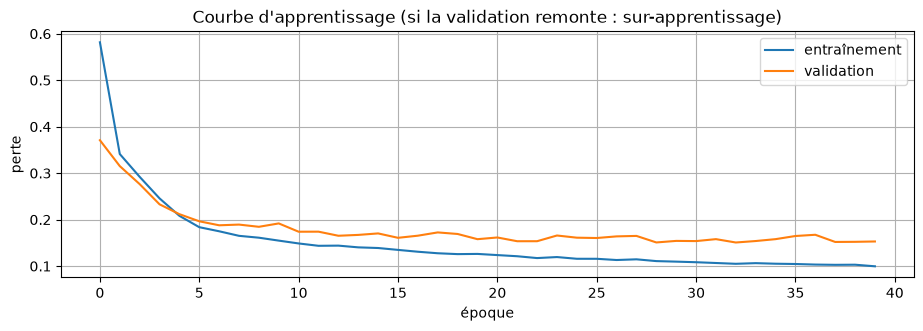

In [9]:
h = np.array(hist)
fig, ax = plt.subplots()
ax.plot(h[:, 0], label="entraînement"); ax.plot(h[:, 1], label="validation")
ax.set_xlabel("époque"); ax.set_ylabel("perte"); ax.set_title("Courbe d'apprentissage (si la validation remonte : sur-apprentissage)")
ax.legend(); rapport("6. Entraînement", "Courbe d'apprentissage", fig); plt.show()

## 7. Prédiction sur le test
Je fais passer toute la période de test dans le réseau en une seule fois, avec 512 minutes de contexte avant le début du test. Pour chaque appareil et chaque minute :
- la **probabilité d'être allumé** est obtenue avec une sigmoïde sur le score ; au-dessus de 0,5, l'appareil est déclaré allumé ;
- la **puissance** est la sortie de régression (partie positive) remultipliée par l'échelle de l'appareil, et mise à 0 quand le réseau dit « éteint ».

In [10]:
net.eval()
out = run(OFF + i_test, OFF + T).cpu().numpy()
reg = np.maximum(out[:n_app], 0) * scale_y[:, None]
p_on = 1 / (1 + np.exp(-out[n_app:]))
on_nn = np.zeros((n_app, T), dtype=bool); on_nn[:, i_test:] = p_on > 0.5
pred_nn = np.zeros((n_app, T), dtype=np.float32); pred_nn[:, i_test:] = reg * (p_on > 0.5)
print("prédiction terminée sur", te.sum(), "minutes de test valides")

prédiction terminée sur 152711 minutes de test valides


## 8. Comparaison : le tableau à retenir
J'utilise les mêmes métriques qu'en semaine 2, calculées **uniquement sur les minutes valides de la période de test** :
- **F1** (0 à 1) : l'appareil est-il détecté allumé au bon moment ? Il combine la **précision** (quand le modèle dit « allumé », a-t-il raison ?) et le **rappel** (retrouve-t-il tous les moments où l'appareil tourne ?) ;
- **MAE (W)** : écart moyen, minute par minute, entre puissance prédite et réelle ;
- **erreur d'énergie (%)** : écart relatif sur les kWh attribués à l'appareil sur toute la période de test. C'est la métrique la plus utile pour la facture et pour la flexibilité.

Pour chaque appareil, la comparaison qui compte est **Réseau contre CO**. Le second tableau résume le gain de F1 et les erreurs d'énergie des deux méthodes.

In [11]:
dt_h = pd.Timedelta(RESAMPLE).total_seconds() / 3600

def metrics(y_true, y_pred, on_pred, thr_a):
    t, p = y_true > thr_a, on_pred
    tp, fp, fn = (t & p).sum(), (~t & p).sum(), (t & ~p).sum()
    e_t, e_p = y_true.sum() * dt_h / 1000, y_pred.sum() * dt_h / 1000
    return {
        "F1": 2 * tp / (2 * tp + fp + fn) if (2 * tp + fp + fn) else np.nan,
        "précision": tp / (tp + fp) if (tp + fp) else np.nan,
        "rappel": tp / (tp + fn) if (tp + fn) else np.nan,
        "MAE (W)": float(np.abs(y_true - y_pred).mean()),
        "kWh réels": e_t, "kWh prédits": e_p,
        "erreur énergie (%)": 100 * abs(e_p - e_t) / e_t if e_t > 0 else np.nan,
    }

rows = []
for method, pred, on in [("Naïf", pred_naive, on_naive), ("CO", pred_co, on_co), ("Réseau", pred_nn, on_nn)]:
    for i, a in enumerate(APPLIANCES):
        rows.append({"appareil": a, "méthode": method, **metrics(Yw[i, te], pred[i, te], on[i, te], thr[i])})
results = pd.DataFrame(rows).set_index(["appareil", "méthode"]).sort_index()
rapport("8. Comparaison", "Métriques sur le test (naïf, CO, réseau)", results.round(2))
results.round(2)

F1  précision  rappel  MAE (W)  kWh réels  \
appareil        méthode                                                
dishwasher      CO       0.06       0.03    0.74    74.79  45.480000   
                Naïf     0.04       0.02    1.00   695.04  45.480000   
                Réseau   0.87       0.78    0.99     7.42  45.480000   
fridge          CO       0.50       0.57    0.44    36.25  98.800003   
                Naïf     0.59       0.42    1.00    58.53  98.800003   
                Réseau   0.81       0.76    0.87    21.24  98.800003   
kettle          CO       0.30       0.22    0.44    29.84  37.349998   
                Naïf     0.02       0.01    1.00  1679.73  37.349998   
                Réseau   0.75       0.64    0.92     8.91  37.349998   
washing_machine CO       0.23       0.14    0.81    85.26  82.180000   
                Naïf     0.10       0.06    1.00   473.27  82.180000   
                Réseau   0.91       0.85    0.99    12.03  82.180000   

                         kWh prédits  erreur énergie (%)  
appareil        méthode                                   
dishwasher      CO        210.729996          363.329987  
                Naïf     1760.910034         3771.729980  
                Réseau     52.209999           14.800000  
fridge          CO         75.650002           23.440001  
                Naïf      235.199997          138.050003  
                Réseau    114.430000           15.820000  
kettle          CO         66.660004           78.470001  
                Naïf     4300.540039        11414.469727  
                Réseau     46.930000           25.660000  
washing_machine CO        183.419998          123.199997  
                Naïf     1191.099976         1349.439941  
                Réseau     83.550003            1.680000

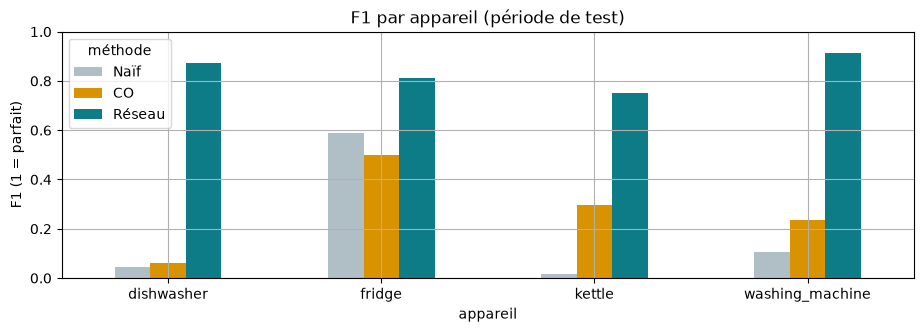

,F1 CO,F1 réseau,gain F1,erreur énergie CO (%),erreur énergie réseau (%)
appareil,,,,,
dishwasher,0.06,0.87,0.81,363.329987,14.80
fridge,0.50,0.81,0.31,23.440001,15.82
kettle,0.30,0.75,0.46,78.470001,25.66
washing_machine,0.23,0.91,0.68,123.199997,1.68


In [12]:
f1 = results["F1"].unstack("méthode")[["Naïf", "CO", "Réseau"]]
ax = f1.plot.bar(rot=0, color=["#B0BEC5", "#D99200", "#0E7C86"], title="F1 par appareil (période de test)", ylim=(0, 1))
ax.set_ylabel("F1 (1 = parfait)"); rapport("8. Comparaison", "F1 par appareil", ax.figure); plt.show()

cmp = pd.DataFrame({"F1 CO": f1["CO"], "F1 réseau": f1["Réseau"], "gain F1": f1["Réseau"] - f1["CO"],
                    "erreur énergie CO (%)": results.xs("CO", level="méthode")["erreur énergie (%)"],
                    "erreur énergie réseau (%)": results.xs("Réseau", level="méthode")["erreur énergie (%)"]})
rapport("8. Comparaison", "Réseau contre CO", cmp.round(2))
cmp.round(2)

## 9. Une journée de test : réel, CO, réseau
Pour voir concrètement le comportement des modèles, j'affiche la journée de test où les 4 appareils consomment le plus d'énergie (le 31 décembre 2013 dans mes exécutions). Pour chaque appareil : la puissance réelle mesurée par sa prise, celle du CO et celle du réseau. On voit si les cycles sont trouvés au bon moment, s'ils ont la bonne durée et si des cycles sont inventés.

jour affiché : 2013-12-31


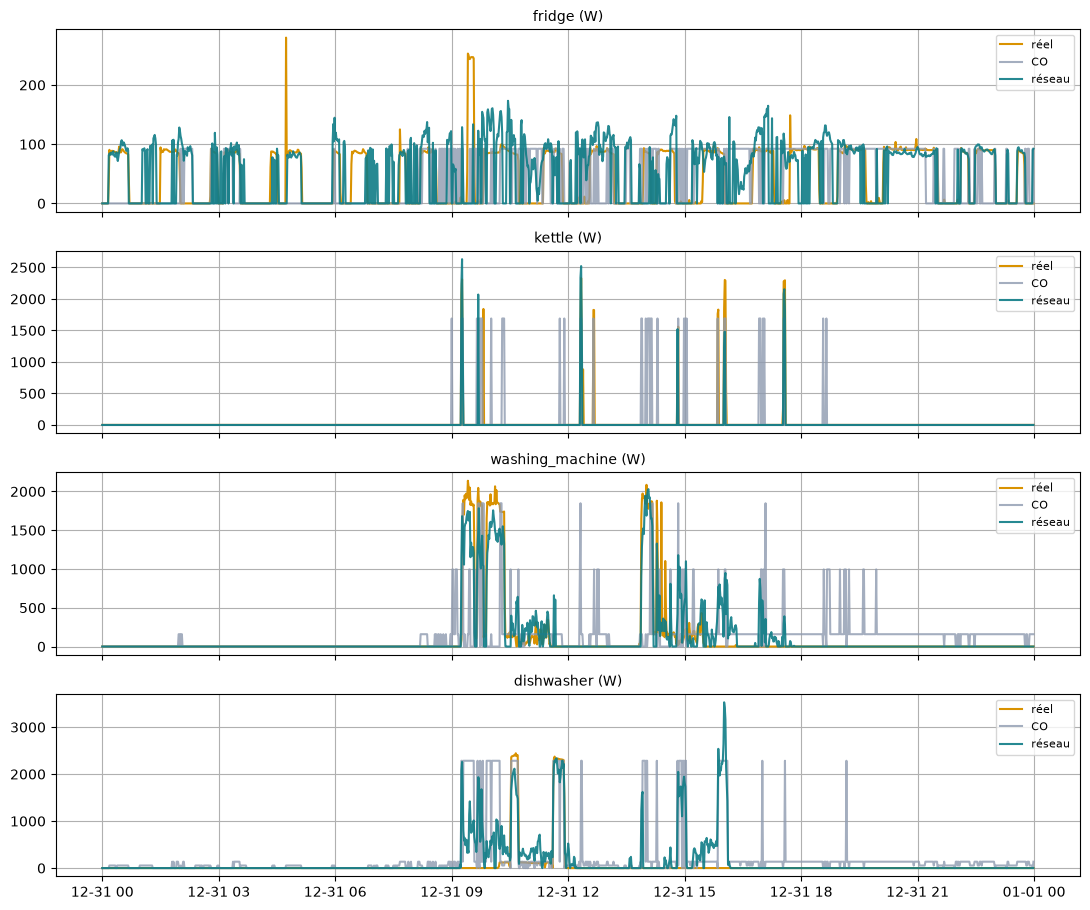

In [13]:
idx_t = data.index[i_test:]
vt = valid[i_test:]
day_energy = pd.Series(Yw[:, i_test:].sum(0)[vt], index=idx_t[vt]).groupby(idx_t[vt].date).sum()
day = str(day_energy.idxmax())                         # jour de test avec le plus d'activité
print("jour affiché :", day)
sel = np.array([str(d.date()) == day for d in data.index])
t_ax = data.index[sel]
fig, axes = plt.subplots(n_app, 1, figsize=(11, 2.3 * n_app), sharex=True)
for ax, i, a in zip(np.atleast_1d(axes), range(n_app), APPLIANCES):
    ax.plot(t_ax, Yw[i, sel], color="#D99200", label="réel")
    ax.plot(t_ax, pred_co[i, sel], color="#8E9AAF", label="CO", alpha=0.8)
    ax.plot(t_ax, pred_nn[i, sel], color="#0E7C86", label="réseau", alpha=0.9)
    ax.set_title(a + " (W)", fontsize=10); ax.legend(loc="upper right", fontsize=8)
plt.tight_layout(); rapport("9. Une journée de test", f"Journée du {day} : réel, CO, réseau", fig); plt.show()

## 10. Matrices de confusion : ce que le modèle réussit… et rate

**Comment je lis une matrice de confusion.** Pour **un** appareil, je prends chaque minute du test et je regarde deux choses : *était-il vraiment allumé ?* (la réalité, mesurée par la prise de l'appareil) et *le modèle a-t-il dit « allumé » ?* (sa prédiction). Cela donne 4 cas :

| | le modèle dit « éteint » | le modèle dit « allumé » |
|---|---|---|
| **réellement éteint** | ✅ **bien éteint** (vrai négatif) | ❌ **fausse alerte** (faux positif) |
| **réellement allumé** | ❌ **raté** (faux négatif) | ✅ **bien détecté** (vrai positif) |

Sur le graphique, **chaque ligne est ramenée à 100 %**, sinon on ne verrait rien : un lave-vaisselle est éteint plus de 95 % du temps. La case en bas à droite est le **rappel** (parmi les minutes où l'appareil tourne vraiment, quelle part le modèle retrouve) et la case en haut à droite le **taux de fausses alertes**. Une bonne matrice a une diagonale foncée (haut-gauche et bas-droite) et des cases claires ailleurs.

**Pourquoi 4 matrices 2×2 et pas une grande ?** Plusieurs appareils peuvent tourner en même temps : ce n'est pas un choix « un appareil parmi quatre », c'est une question oui/non posée séparément pour chaque appareil.

**Ce que fait le modèle, en clair.** Pour chaque minute, il regarde la courbe de la maison sur environ 4 heures autour d'elle et sort, pour chaque appareil, une **probabilité d'être allumé**. Au-dessus de **50 %**, il dit « allumé ». Le CO, lui, ne regarde que la valeur de la minute et choisit la combinaison d'appareils qui s'en rapproche le plus.

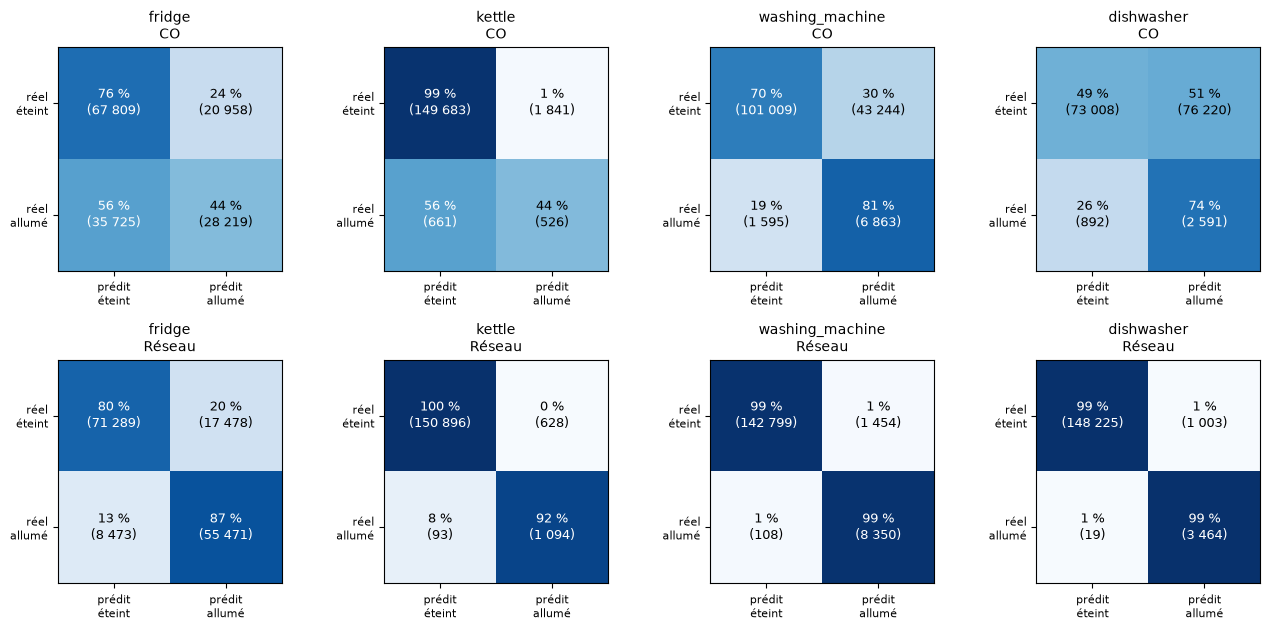

bien éteint  fausses alertes  ratés  bien détecté
appareil        méthode                                                   
dishwasher      CO             73008            76220    892          2591
                Réseau        148225             1003     19          3464
fridge          CO             67809            20958  35725         28219
                Réseau         71289            17478   8473         55471
kettle          CO            149683             1841    661           526
                Réseau        150896              628     93          1094
washing_machine CO            101009            43244   1595          6863
                Réseau        142799             1454    108          8350

In [14]:
def confusion(y_true, on_pred, thr_a):
    # lignes : réalité (éteint, allumé) ; colonnes : prédiction (éteint, allumé)
    t, p = y_true > thr_a, on_pred
    return np.array([[(~t & ~p).sum(), (~t & p).sum()],
                     [(t & ~p).sum(),  (t & p).sum()]])

fig, axes = plt.subplots(2, n_app, figsize=(3.3 * n_app, 6.4))
axes = np.array(axes).reshape(2, n_app)
cms = {}
for r, (method, on) in enumerate([("CO", on_co), ("Réseau", on_nn)]):
    for i, a in enumerate(APPLIANCES):
        cm = confusion(Yw[i, te], on[i, te], thr[i]); cms[(method, a)] = cm
        pct = cm / np.maximum(cm.sum(1, keepdims=True), 1) * 100
        ax = axes[r, i]
        ax.imshow(pct, cmap="Blues", vmin=0, vmax=100)
        for u in range(2):
            for v in range(2):
                ax.text(v, u, f"{pct[u, v]:.0f} %\n({cm[u, v]:,})".replace(",", " "), ha="center", va="center",
                        fontsize=9, color="white" if pct[u, v] > 55 else "black")
        ax.set_xticks([0, 1]); ax.set_xticklabels(["prédit\néteint", "prédit\nallumé"], fontsize=8)
        ax.set_yticks([0, 1]); ax.set_yticklabels(["réel\néteint", "réel\nallumé"], fontsize=8)
        ax.set_title(f"{a}\n{method}", fontsize=10); ax.grid(False)
plt.tight_layout(); rapport("10. Matrices de confusion", "Matrices de confusion (% par ligne)", fig); plt.show()

conf_rows = []
for (method, a), cm in cms.items():
    conf_rows.append({"appareil": a, "méthode": method, "bien éteint": cm[0, 0], "fausses alertes": cm[0, 1],
                      "ratés": cm[1, 0], "bien détecté": cm[1, 1]})
conf_tab = pd.DataFrame(conf_rows).set_index(["appareil", "méthode"]).sort_index()
rapport("10. Matrices de confusion", "Matrices de confusion (minutes)", conf_tab)
conf_tab

### Ce que ça veut dire, appareil par appareil
La cellule suivante traduit automatiquement chaque matrice en phrases, à partir des chiffres :
- **Rappel** : sur 100 minutes où l'appareil tourne vraiment, combien le modèle en retrouve ;
- **Précision** : sur 100 minutes où le modèle annonce « allumé », combien sont vraies ;
- **Fausses alertes** : part des minutes éteintes où le modèle se trompe.

Ces deux grandeurs ne s'améliorent pas ensemble : un modèle qui dit « allumé » à tout va a un rappel parfait et une précision très faible (c'est exactement le modèle naïf).

In [15]:
def fmt(x, pct=True):
    return "n/a" if not np.isfinite(x) else (f"{100 * x:.0f} %" if pct else f"{x:.1f}")

conf_txt = []
for a in APPLIANCES:
    conf_txt.append(f"=== {a} ===")
    for method in ["CO", "Réseau"]:
        tn, fp, fn, tp = cms[(method, a)].ravel()
        rappel = tp / (tp + fn) if tp + fn else np.nan
        prec = tp / (tp + fp) if tp + fp else np.nan
        fa = fp / (fp + tn) if fp + tn else np.nan
        k_ = lambda v: f"{v:,}".replace(",", " ")
        conf_txt.append(f"  {method:7s} retrouve {fmt(rappel)} des minutes où l'appareil tourne ; "
              f"quand il dit « allumé », il a raison {fmt(prec)} du temps ; "
              f"{k_(fp)} fausses alertes ({fmt(fa)} des minutes éteintes), {k_(fn)} minutes ratées.")
print("\n".join(conf_txt))
rapport("10. Matrices de confusion", "Lecture des matrices, appareil par appareil", "\n".join(conf_txt))

=== fridge ===
  CO      retrouve 44 % des minutes où l'appareil tourne ; quand il dit « allumé », il a raison 57 % du temps ; 20 958 fausses alertes (24 % des minutes éteintes), 35 725 minutes ratées.
  Réseau  retrouve 87 % des minutes où l'appareil tourne ; quand il dit « allumé », il a raison 76 % du temps ; 17 478 fausses alertes (20 % des minutes éteintes), 8 473 minutes ratées.
=== kettle ===
  CO      retrouve 44 % des minutes où l'appareil tourne ; quand il dit « allumé », il a raison 22 % du temps ; 1 841 fausses alertes (1 % des minutes éteintes), 661 minutes ratées.
  Réseau  retrouve 92 % des minutes où l'appareil tourne ; quand il dit « allumé », il a raison 64 % du temps ; 628 fausses alertes (0 % des minutes éteintes), 93 minutes ratées.
=== washing_machine ===
  CO      retrouve 81 % des minutes où l'appareil tourne ; quand il dit « allumé », il a raison 14 % du temps ; 43 244 fausses alertes (30 % des minutes éteintes), 1 595 minutes ratées.
  Réseau  retrouve 99 % de

### Le seuil de décision (le « 50 % » du réseau)
Le réseau sort une probabilité ; c'est moi qui fixe à partir de quand je dis « allumé ». **Baisser le seuil** fait détecter plus de cycles (rappel ↑) mais avec plus d'erreurs (précision ↓) ; **le monter** fait l'inverse. Les courbes tracent ce compromis pour chaque appareil, avec le point correspondant à 0,5. Le seuil de 0,5 est un choix raisonnable, pas une obligation : pour piloter des équipements (flexibilité), on peut préférer un seuil plus élevé pour n'agir que lorsque le modèle est sûr de lui.

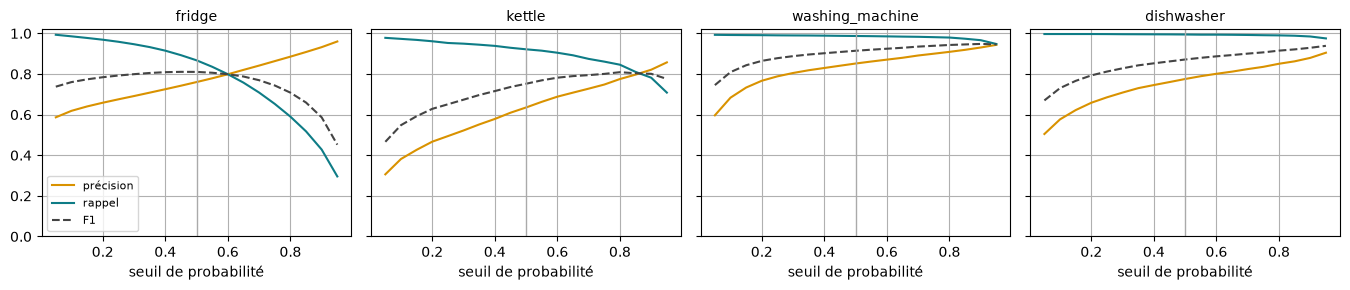

In [16]:
ths = np.linspace(0.05, 0.95, 19)
m_te = te[i_test:]
fig, axes = plt.subplots(1, n_app, figsize=(3.4 * n_app, 3.0), sharey=True)
for ax, i, a in zip(np.atleast_1d(axes), range(n_app), APPLIANCES):
    t = (Yw[i, i_test:] > thr[i])[m_te]; pr = p_on[i][m_te]
    prec_, rap_, f1_ = [], [], []
    for th in ths:
        p = pr > th; tp, fp, fn = (t & p).sum(), (~t & p).sum(), (t & ~p).sum()
        prec_.append(tp / (tp + fp) if tp + fp else np.nan); rap_.append(tp / (tp + fn) if tp + fn else np.nan)
        f1_.append(2 * tp / (2 * tp + fp + fn) if (2 * tp + fp + fn) else np.nan)
    ax.plot(ths, prec_, label="précision", color="#D99200"); ax.plot(ths, rap_, label="rappel", color="#0E7C86")
    ax.plot(ths, f1_, label="F1", color="#444", ls="--"); ax.axvline(0.5, color="#aaa", lw=1)
    ax.set_title(a, fontsize=10); ax.set_xlabel("seuil de probabilité"); ax.set_ylim(0, 1.02)
np.atleast_1d(axes)[0].legend(fontsize=8); plt.tight_layout()
rapport("10. Matrices de confusion", "Seuil de décision du réseau", fig); plt.show()

## 11. Flexibilité : adapter la consommation au prix de l'électricité

**Demande du client :** montrer qu'on peut décaler une partie de la consommation vers les moments où l'électricité est moins chère, avec deux leviers : le **chauffe-eau** (stocker de la chaleur dans la cuve) et une **batterie locale**.

**Ce qui est mesuré, ce qui est simulé.** La consommation de la maison vient des **vraies mesures** UK-DALE de la période de test (107 jours complets, 9,3 kWh/jour en moyenne). La maison UK-DALE n'a pas de chauffe-eau électrique ni de batterie : je les **simule** avec des paramètres réalistes réglables en tête de cellule :
- chauffe-eau : cuve de 7 kWh de chaleur (≈ 200 L), résistance de 2 kW, besoin de 5 kWh/jour réparti sur les heures de puisage, 1 %/h de pertes, stock minimal garanti ;
- batterie : 5 kWh, 2,5 kW, rendement de 95 % à la charge et à la décharge, pas de revente au réseau.

**Les prix.** Deux signaux : un **tarif heures pleines / heures creuses** (0,27 / 0,21 €/kWh, heures creuses de 22 h à 6 h) et un **prix dynamique** horaire. Faute de vrais prix pour l'instant, le prix dynamique est *synthétique* mais de forme réaliste (pointes le matin et le soir, creux la nuit et en milieu de journée, 0,165 €/kWh en moyenne) ; il peut être remplacé par de vrais prix horaires avec un fichier `prix.csv` (colonnes `time,eur_kwh`).

**Les 4 scénarios**, comparés sur les mêmes jours et les mêmes prix :
1. **Référence** : chauffe-eau avec thermostat classique (il relance dès que la cuve descend sous 75 %, quel que soit le prix), pas de batterie ;
2. **Chauffe-eau piloté** : il chauffe aux heures les moins chères de la journée, en gardant toujours de l'eau chaude ;
3. **Batterie seule** : elle se charge quand l'électricité est bon marché et se décharge quand elle est chère ;
4. **Chauffe-eau + batterie**, optimisés ensemble.

Le pilotage est un petit problème d'optimisation linéaire (`scipy.optimize.linprog`) résolu **jour par jour, au pas horaire**, avec les prix du jour connus à l'avance (comme les prix « day-ahead » du marché). Le résultat est donc un **plafond de ce qu'on peut gagner**, pas ce qu'obtiendrait un vrai régulateur avec des prévisions imparfaites.

In [17]:
from scipy.optimize import linprog

# ================== RÉGLAGES FLEXIBILITÉ (à adapter) ==================
PRIX_HP, PRIX_HC = 0.27, 0.21                 # €/kWh heures pleines / creuses (ordre de grandeur : à remplacer par ton tarif)
HC_HOURS = [22, 23, 0, 1, 2, 3, 4, 5]         # heures creuses (8 h par nuit)
PRIX_DYN_FILE = DATA_DIR / "prix.csv"         # optionnel : colonnes time,eur_kwh (une ligne par heure, mêmes dates que le test)
# Chauffe-eau (simulé)
WH_CAP = 7.0        # kWh de chaleur stockables dans la cuve (≈ 200 L, 30 °C d'écart)
WH_P = 2.0          # puissance de chauffe (kW)
WH_DAY = 5.0        # besoin d'eau chaude par jour (kWh)
WH_LOSS = 0.01      # pertes par heure (fraction du stock)
WH_MIN = 1.0        # stock minimal à tout moment (confort : il reste de l'eau chaude)
WH_LOW = 0.75       # thermostat classique : relance quand le stock passe sous 75 %
WH_END = 0.6        # le soir, on veut au moins 60 % de stock pour le lendemain matin
DRAW = np.zeros(24)
for h_, w_ in {6: .10, 7: .20, 8: .10, 12: .05, 13: .05, 18: .10, 19: .15, 20: .10, 21: .10, 22: .05}.items():
    DRAW[h_] = w_ * WH_DAY                    # soutirage d'eau chaude par heure (kWh)
# Batterie (simulée)
BAT_CAP, BAT_P, BAT_ETA = 5.0, 2.5, 0.95      # capacité kWh, puissance kW, rendement à la charge et à la décharge
BAT_SOC_MIN, BAT_START, BAT_END = 0.5, 2.5, 2.5   # stock minimal, de départ et de fin de journée (kWh)
SHIFT_APPS = ["washing_machine", "dishwasher"]    # appareils décalables (section 12)
SHIFT_WINDOW = (0, 24)                            # heures où l'on accepte de lancer un cycle décalé
# =====================================================================

# --- consommation horaire de la maison (vraies mesures, période de test) ---
s_agg = pd.Series(np.where(valid, agg, np.nan), index=data.index).iloc[i_test:]
hourly = s_agg.resample("1h").mean() / 1000.0                 # kWh consommés pendant chaque heure
by_day = hourly.groupby(hourly.index.date)
ok_days = [d for d, x in by_day if len(x) == 24 and x.isna().sum() <= 2]
if len(ok_days) < 3:
    raise SystemExit("Pas assez de jours complets dans le test pour simuler la flexibilité.")
hourly = hourly[[d in set(ok_days) for d in hourly.index.date]].ffill().bfill()
D = len(ok_days)
hours_idx = hourly.index
base = hourly.values.reshape(D, 24)                           # (jours, 24) kWh/h
print(f"{D} jours complets de test, du {ok_days[0]} au {ok_days[-1]} ; consommation moyenne {base.sum() / D:.1f} kWh/jour")

# --- signaux de prix (€/kWh) ---
hod = hours_idx.hour.values
price_hphc = np.where(np.isin(hod, HC_HOURS), PRIX_HC, PRIX_HP).reshape(D, 24)
if PRIX_DYN_FILE.exists():
    pr = pd.read_csv(PRIX_DYN_FILE, parse_dates=["time"]).set_index("time")["eur_kwh"]
    pser = pr.reindex(hours_idx).ffill().bfill()
    price_dyn = pser.values.reshape(D, 24); PRIX_DYN_SOURCE = "fichier prix.csv"
else:
    rng = np.random.default_rng(1)
    hh = np.arange(24)
    shape = (1 + 0.35 * np.exp(-((hh - 8) / 1.8) ** 2) + 0.60 * np.exp(-((hh - 19) / 2.0) ** 2)
             - 0.30 * np.exp(-((hh - 13.5) / 2.5) ** 2) - 0.25 * np.exp(-((hh - 3.5) / 3.0) ** 2))
    day_factor = np.exp(rng.normal(0, 0.25, size=(D, 1)))
    price_dyn = np.clip(0.16 * day_factor * shape[None, :] * (1 + rng.normal(0, 0.05, size=(D, 24))), 0.03, None)
    PRIX_DYN_SOURCE = "synthétique (à remplacer par de vrais prix)"
PRICES = {"HP/HC": price_hphc, "dynamique": price_dyn}
flex_ctx = [f"{D} jours complets de test, du {ok_days[0]} au {ok_days[-1]} ; consommation moyenne {base.sum() / D:.1f} kWh/jour",
            f"prix HP/HC : {PRIX_HP} / {PRIX_HC} €/kWh, heures creuses {HC_HOURS}",
            f"prix dynamique : {PRIX_DYN_SOURCE} | moyen {price_dyn.mean():.3f} €/kWh, min {price_dyn.min():.3f}, max {price_dyn.max():.3f}",
            f"chauffe-eau : {WH_CAP} kWh, {WH_P} kW, besoin {WH_DAY} kWh/jour | batterie : {BAT_CAP} kWh, {BAT_P} kW, rendement {BAT_ETA}"]
print(flex_ctx[-2])
rapport("11. Flexibilité", "Hypothèses de la simulation", "\n".join(flex_ctx))

107 jours complets de test, du 2013-11-12 au 2014-02-28 ; consommation moyenne 9.3 kWh/jour
prix dynamique : synthétique (à remplacer par de vrais prix) | moyen 0.165 €/kWh, min 0.054, max 0.459


In [18]:
def thermostat_day(e0, heating0):
    # chauffe-eau classique : relance sous WH_LOW, chauffe jusqu'au plein, sans regarder le prix
    h = np.zeros(24); e = e0; heating = heating0
    for t in range(24):
        e_pre = e * (1 - WH_LOSS) - DRAW[t]
        if e_pre < WH_LOW * WH_CAP: heating = True
        if heating:
            h[t] = min(WH_P, WH_CAP - e_pre)
            if e_pre + h[t] >= WH_CAP - 1e-9: heating = False
        e = e_pre + h[t]
    return h, e, heating

def optimise_day(price, base_d, e0, s0, wh_flex, bat_on, h_fixed):
    # programme linéaire sur 24 h : minimise le coût d'achat, sous contraintes de stock (cuve, batterie)
    n = 24; nv = 5 * n
    ih, ic, idd, ie, isoc = (slice(k * n, (k + 1) * n) for k in range(5))
    cost = np.concatenate([price, price, -price, np.zeros(n), np.zeros(n)])
    Aeq = np.zeros((2 * n, nv)); beq = np.zeros(2 * n)
    for t in range(n):
        Aeq[t, ie.start + t] = 1; Aeq[t, ih.start + t] = -1                 # e_t = (1-L) e_{t-1} + h_t - soutirage_t
        if t > 0: Aeq[t, ie.start + t - 1] = -(1 - WH_LOSS)
        beq[t] = DRAW[t] * -1 + ((1 - WH_LOSS) * e0 if t == 0 else 0)
        r = n + t
        Aeq[r, isoc.start + t] = 1; Aeq[r, ic.start + t] = -BAT_ETA; Aeq[r, idd.start + t] = 1 / BAT_ETA   # s_t = s_{t-1} + eta c - d/eta
        if t > 0: Aeq[r, isoc.start + t - 1] = -1
        beq[r] = s0 if t == 0 else 0
    Aub = np.zeros((n, nv)); bub = np.zeros(n)
    for t in range(n):
        Aub[t, idd.start + t] = 1; Aub[t, ih.start + t] = -1; bub[t] = base_d[t]   # on ne décharge que pour couvrir la consommation
    b = [(0, WH_P) if wh_flex else (h_fixed[t], h_fixed[t]) for t in range(n)]
    b += [(0, BAT_P) if bat_on else (0, 0) for _ in range(n)] * 2
    b += [(WH_MIN if wh_flex else 0, WH_CAP + 1e-6) for _ in range(n)]
    if wh_flex: b[3 * n + n - 1] = (max(WH_MIN, WH_END * WH_CAP), WH_CAP + 1e-6)
    b += [(BAT_SOC_MIN, BAT_CAP) if bat_on else (s0, s0) for _ in range(n)]
    if bat_on: b[4 * n + n - 1] = (max(BAT_SOC_MIN, BAT_END), BAT_CAP)
    res = linprog(cost, A_ub=Aub, b_ub=bub, A_eq=Aeq, b_eq=beq, bounds=b, method="highs")
    if res.status != 0: return None
    x = res.x
    return x[ih], x[ic], x[idd], x[ie], x[isoc]

def run_scenario(price_arr, wh_flex, bat_on):
    e, heating, s = WH_CAP, False, (BAT_START if bat_on else 0.0)
    H = np.zeros((D, 24)); C = np.zeros((D, 24)); Dis = np.zeros((D, 24)); S = np.zeros((D, 24)); fails = 0
    for k in range(D):
        h_th, e_th, heating_th = thermostat_day(e, heating)
        res = optimise_day(price_arr[k], base[k], e, s, wh_flex, bat_on, h_th) if (wh_flex or bat_on) else None
        if res is None:
            if wh_flex or bat_on: fails += 1
            H[k] = h_th; e, heating = e_th, heating_th
            S[k] = s
        else:
            H[k], C[k], Dis[k], e_arr, S[k] = res
            e = e_arr[-1]; s = S[k][-1] if bat_on else s
            heating = e < WH_LOW * WH_CAP
            if not wh_flex: e, heating = e_th, heating_th        # le thermostat garde son propre état
    load = base + H + C - Dis                                  # kWh achetés au réseau, par heure
    return {"H": H, "C": C, "D": Dis, "S": S, "load": load, "cost": float((load * price_arr).sum()), "fails": fails}

SCEN = [("1. Référence", False, False), ("2. Chauffe-eau piloté", True, False),
        ("3. Batterie seule", False, True), ("4. Chauffe-eau + batterie", True, True)]
sim = {}
rows = []
for pm, parr in PRICES.items():
    ref_cost = None
    for name, wf, bo in SCEN:
        r = run_scenario(parr, wf, bo); sim[(pm, name)] = r
        if ref_cost is None: ref_cost = r["cost"]
        rows.append({"prix": pm, "scénario": name, "coût sur la période (€)": r["cost"], "coût par jour (€)": r["cost"] / D,
                     "économie (€)": ref_cost - r["cost"], "économie (%)": 100 * (ref_cost - r["cost"]) / ref_cost,
                     "énergie achetée (kWh)": r["load"].sum(), "pic horaire (kW)": r["load"].max(),
                     "jours en secours": r["fails"]})
flex_res = pd.DataFrame(rows).set_index(["prix", "scénario"])
rapport("11. Flexibilité", "Les 4 scénarios de flexibilité", flex_res.round(2))
flex_res.round(2)

coût sur la période (€)  \
prix      scénario                                             
HP/HC     1. Référence                                441.34   
          2. Chauffe-eau piloté                       386.48   
          3. Batterie seule                           424.27   
          4. Chauffe-eau + batterie                   369.89   
dynamique 1. Référence                                308.13   
          2. Chauffe-eau piloté                       248.45   
          3. Batterie seule                           243.55   
          4. Chauffe-eau + batterie                   207.43   

                                     coût par jour (€)  économie (€)  \
prix      scénario                                                     
HP/HC     1. Référence                            4.12          0.00   
          2. Chauffe-eau piloté                   3.61         54.85   
          3. Batterie seule                       3.97         17.07   
          4. Chauffe-eau + batterie               3.46         71.45   
dynamique 1. Référence                            2.88          0.00   
          2. Chauffe-eau piloté                   2.32         59.69   
          3. Batterie seule                       2.28         64.58   
          4. Chauffe-eau + batterie               1.94        100.70   

                                     économie (%)  énergie achetée (kWh)  \
prix      scénario                                                         
HP/HC     1. Référence                       0.00                1684.45   
          2. Chauffe-eau piloté             12.43                1620.72   
          3. Batterie seule                  3.87                1733.86   
          4. Chauffe-eau + batterie         16.19                1666.89   
dynamique 1. Référence                       0.00                1684.45   
          2. Chauffe-eau piloté             19.37                1636.16   
          3. Batterie seule                 20.96                1786.88   
          4. Chauffe-eau + batterie         32.68                1704.15   

                                     pic horaire (kW)  jours en secours  
prix      scénario                                                       
HP/HC     1. Référence                           4.01                 0  
          2. Chauffe-eau piloté                  3.23                 0  
          3. Batterie seule                      4.01                 0  
          4. Chauffe-eau + batterie              5.33                 0  
dynamique 1. Référence                           4.01                 0  
          2. Chauffe-eau piloté                  3.66                 0  
          3. Batterie seule                      4.03                 0  
          4. Chauffe-eau + batterie              6.03                 0

### Lire le tableau et les graphiques
- **Économie (%)** : gain par rapport au scénario 1 avec le **même signal de prix**. Avec le tarif HP/HC, seul le décalage vers la nuit rapporte ; avec un prix dynamique, il y a davantage de variations à exploiter.
- **Énergie achetée** : avec la batterie, j'achète un peu plus de kWh que la maison n'en consomme (pertes de charge et de décharge). L'économie vient du **prix** auquel l'énergie est achetée, pas du volume.
- **Pic horaire** : la puissance maximale tirée sur une heure. Tout décaler vers les heures creuses peut créer un **nouveau pic la nuit**, qu'il faudra surveiller (puissance souscrite).
- **Jours en secours** : jours où l'optimiseur n'aurait pas trouvé de solution et où je reviens au thermostat ; il doit valoir 0.
- La cellule donne aussi un ordre de grandeur annuel (×365/107). Ce n'est pas un gain « garanti » : les prix sont connus à l'avance, la batterie est parfaite (pas d'usure) et le coût du matériel n'est pas compté.

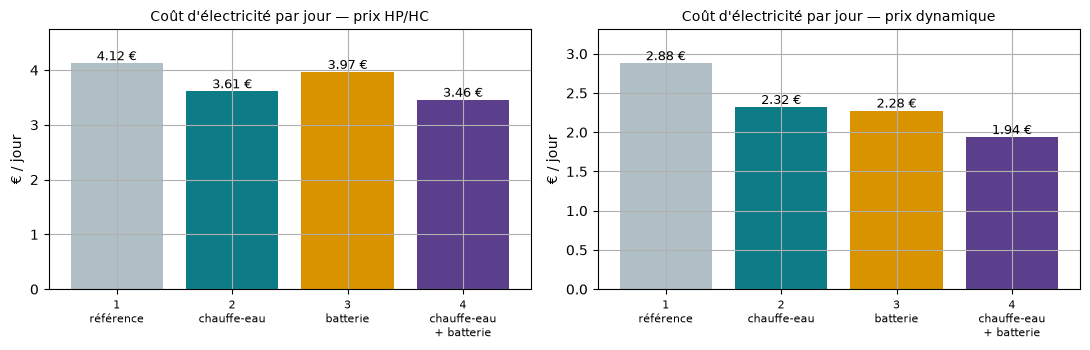

Ordre de grandeur annuel (×365/107) :
  prix HP/HC      2. Chauffe-eau piloté        économie ≈    187 € / an
  prix HP/HC      3. Batterie seule            économie ≈     58 € / an
  prix HP/HC      4. Chauffe-eau + batterie    économie ≈    244 € / an
  prix dynamique  2. Chauffe-eau piloté        économie ≈    204 € / an
  prix dynamique  3. Batterie seule            économie ≈    220 € / an
  prix dynamique  4. Chauffe-eau + batterie    économie ≈    344 € / an


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=False)
cols = ["#B0BEC5", "#0E7C86", "#D99200", "#5B3F8C"]
for ax, pm in zip(axes, PRICES):
    vals = [sim[(pm, n)]["cost"] / D for n, _, _ in SCEN]
    bars = ax.bar(range(4), vals, color=cols)
    for b_, v in zip(bars, vals): ax.text(b_.get_x() + b_.get_width() / 2, v, f"{v:.2f} €", ha="center", va="bottom", fontsize=9)
    ax.set_xticks(range(4)); ax.set_xticklabels(["1\nréférence", "2\nchauffe-eau", "3\nbatterie", "4\nchauffe-eau\n+ batterie"], fontsize=8)
    ax.set_title(f"Coût d'électricité par jour — prix {pm}", fontsize=10); ax.set_ylabel("€ / jour")
    ax.set_ylim(0, max(vals) * 1.15)
plt.tight_layout(); rapport("11. Flexibilité", "Coût d'électricité par jour", fig); plt.show()
annuel = [f"Ordre de grandeur annuel (×365/{D}) :"]
for pm in PRICES:
    ref = sim[(pm, SCEN[0][0])]["cost"] / D * 365
    for n, _, _ in SCEN[1:]:
        annuel.append(f"  prix {pm:10s} {n:28s} économie ≈ {ref - sim[(pm, n)]['cost'] / D * 365:6.0f} € / an")
print("\n".join(annuel))
rapport("11. Flexibilité", "Économie annuelle (ordre de grandeur)", "\n".join(annuel))

### Une journée type : qui fait quoi
J'ai choisi le jour où l'écart de prix dynamique entre l'heure la plus chère et la moins chère est le plus grand. En haut, le **prix**. Au milieu, la **puissance du chauffe-eau** : le thermostat (scénario 1) chauffe quand la cuve se vide, alors que le pilotage (scénarios 2 et 4) déplace la chauffe vers les heures bon marché. En bas, la **batterie** (scénario 4) : barres vers le haut pour la charge, vers le bas pour la décharge, et la courbe donne son niveau de charge.

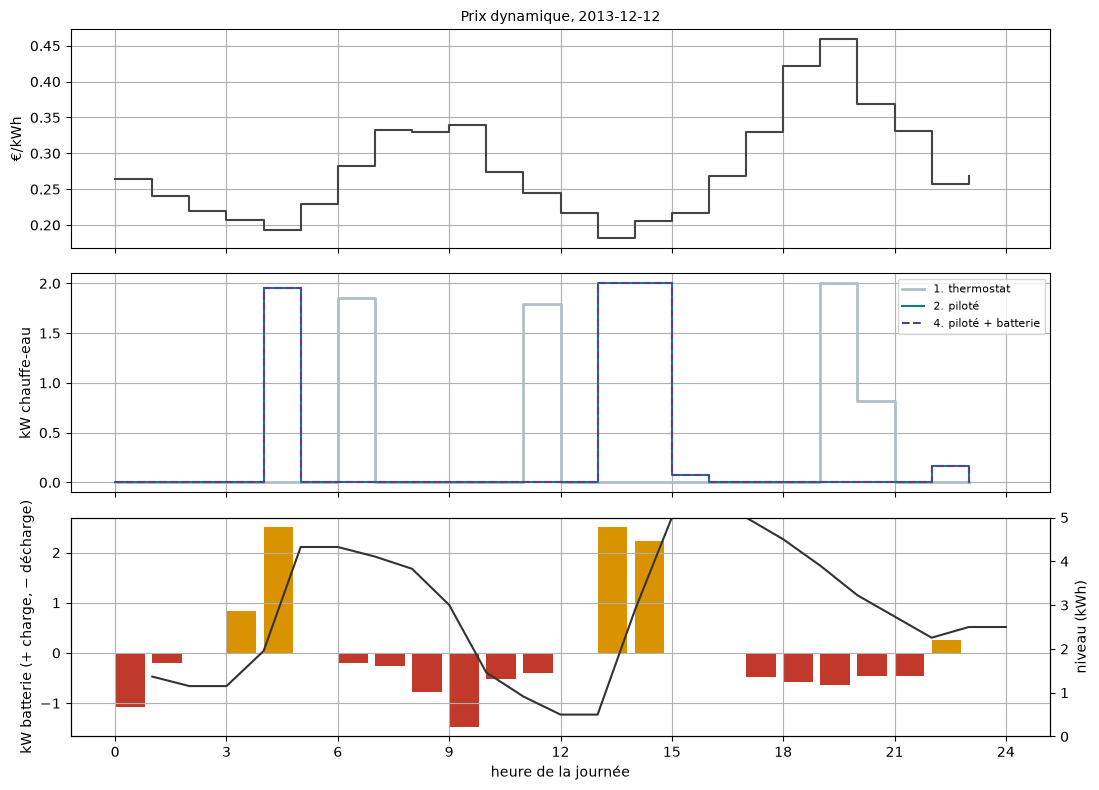

In [20]:
pm = "dynamique"
k = int(np.argmax(price_dyn.max(1) - price_dyn.min(1)))
hh = np.arange(24)
r1, r2, r4 = sim[(pm, SCEN[0][0])], sim[(pm, SCEN[1][0])], sim[(pm, SCEN[3][0])]
fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
axes[0].step(hh, price_dyn[k], where="post", color="#444"); axes[0].set_ylabel("€/kWh"); axes[0].set_title(f"Prix dynamique, {ok_days[k]}", fontsize=10)
axes[1].step(hh, r1["H"][k], where="post", color="#B0BEC5", lw=2, label="1. thermostat")
axes[1].step(hh, r2["H"][k], where="post", color="#0E7C86", label="2. piloté")
axes[1].step(hh, r4["H"][k], where="post", color="#5B3F8C", ls="--", label="4. piloté + batterie")
axes[1].set_ylabel("kW chauffe-eau"); axes[1].legend(fontsize=8, loc="upper right")
axes[2].bar(hh, r4["C"][k] - r4["D"][k], color=np.where(r4["C"][k] - r4["D"][k] >= 0, "#D99200", "#C0392B"), width=0.8, align="edge")
axes[2].set_ylabel("kW batterie (+ charge, − décharge)")
ax2 = axes[2].twinx(); ax2.plot(hh + 1, r4["S"][k], color="#333"); ax2.set_ylabel("niveau (kWh)"); ax2.set_ylim(0, BAT_CAP); ax2.grid(False)
axes[2].set_xlabel("heure de la journée"); axes[2].set_xticks(range(0, 25, 3))
plt.tight_layout(); rapport("11. Flexibilité", f"Journée type ({ok_days[k]}) : qui fait quoi", fig); plt.show()

## 12. Ce que la désagrégation apporte à la flexibilité
Le chauffe-eau et la batterie se pilotent **sans** savoir ce que font les autres appareils. En revanche, le lave-linge et le lave-vaisselle sont eux aussi décalables, et pour les décaler il faut **savoir quand ils tournent et combien ils consomment** : c'est précisément le rôle du modèle NILM.

Pour ces deux appareils, je compare donc l'énergie qu'ils consomment **vraiment**, celle que **le réseau** ou **le CO** leur attribue, et l'économie **potentielle** si, chaque jour, toute cette énergie était déplacée à l'heure la moins chère de la plage autorisée (`SHIFT_WINDOW`). C'est un plafond simplifié (un cycle dure plusieurs heures et l'utilisateur doit être d'accord), mais il répond à la question : **la désagrégation est-elle assez fiable pour chiffrer la flexibilité ?** Si l'économie estimée à partir du modèle est proche de l'économie réelle, oui ; sinon, il faudrait la compléter par une mesure directe (prise connectée).

In [21]:
def hourly_app(sig, a):
    i = APPLIANCES.index(a)
    s = pd.Series(np.where(valid, sig[i], np.nan), index=data.index).iloc[i_test:]
    return (s.resample("1h").mean() / 1000.0).reindex(hours_idx).fillna(0).values.reshape(D, 24)

w0, w1 = SHIFT_WINDOW
rows = []
for pm, parr in PRICES.items():
    pmin = parr[:, w0:w1].min(1)                                  # prix le plus bas de la fenêtre, chaque jour
    for a in [x for x in SHIFT_APPS if x in APPLIANCES]:
        for src, sig in [("réel", Yw), ("réseau", pred_nn), ("CO", pred_co)]:
            e = hourly_app(sig, a)
            now = float((e * parr).sum()); shifted = float((e.sum(1) * pmin).sum())
            rows.append({"prix": pm, "appareil": a, "source": src, "énergie (kWh)": e.sum(),
                         "coût actuel (€)": now, "économie potentielle (€)": now - shifted})
shift_res = pd.DataFrame(rows).set_index(["prix", "appareil", "source"])
shift_tab = shift_res.round(2)
print("Économie potentielle sur la période de test, si tout est décalé à l'heure la moins chère :")
rapport("12. Désagrégation et flexibilité", "Économie potentielle des appareils décalables", shift_tab)
shift_tab

Économie potentielle sur la période de test, si tout est décalé à l'heure la moins chère :


énergie (kWh)  coût actuel (€)  \
prix      appareil        source                                   
HP/HC     washing_machine réel        80.550003            21.64   
                          réseau      82.660004            22.21   
                          CO         181.929993            48.13   
          dishwasher      réel        43.910000            10.41   
                          réseau      50.869999            12.28   
                          CO         209.669998            53.93   
dynamique washing_machine réel        80.550003            13.63   
                          réseau      82.660004            13.69   
                          CO         181.929993            34.10   
          dishwasher      réel        43.910000             7.15   
                          réseau      50.869999             8.37   
                          CO         209.669998            36.78   

                                  économie potentielle (€)  
prix      appareil        source                            
HP/HC     washing_machine réel                        4.72  
                          réseau                      4.85  
                          CO                          9.93  
          dishwasher      réel                        1.19  
                          réseau                      1.60  
                          CO                          9.90  
dynamique washing_machine réel                        4.70  
                          réseau                      4.67  
                          CO                         13.89  
          dishwasher      réel                        2.18  
                          réseau                      2.66  
                          CO                         13.61

In [22]:
tab = shift_res["économie potentielle (€)"].unstack("source")[["réel", "réseau", "CO"]]
tab["écart réseau (%)"] = 100 * (tab["réseau"] - tab["réel"]) / tab["réel"].where(tab["réel"].abs() > 1e-9)
tab["écart CO (%)"] = 100 * (tab["CO"] - tab["réel"]) / tab["réel"].where(tab["réel"].abs() > 1e-9)
print("Économie potentielle en € (et écart par rapport au réel) :")
rapport("12. Désagrégation et flexibilité", "Économie potentielle : écart au réel", tab.round(2))
tab.round(2)

Économie potentielle en € (et écart par rapport au réel) :


source                     réel  réseau     CO  écart réseau (%)  écart CO (%)
prix      appareil                                                            
HP/HC     dishwasher       1.19    1.60   9.90             33.69        728.97
          washing_machine  4.72    4.85   9.93              2.82        110.31
dynamique dishwasher       2.18    2.66  13.61             22.48        525.90
          washing_machine  4.70    4.67  13.89             -0.65        195.65

## 13. Effet des données simulées : réel contre simulé
Cette section répond à trois questions :
1. **Le réseau marche-t-il sur un foyer simulé qu'il n'a jamais vu ?** (le foyer mis de côté en section 3b) ;
2. **Marche-t-il aussi bien sur le réel (UK-DALE) que sur le simulé ?** La différence s'appelle l'*écart simulé → réel* : un score bien meilleur sur le simulé que sur le réel voudrait dire que le simulateur est « trop propre » par rapport à la vraie vie ; un score plus faible sur le simulé montre surtout que le modèle a du mal à passer à une maison qu'il ne connaît pas ;
3. **Ajouter du simulé à l'entraînement améliore-t-il le test réel ?** Pour cela, il faut avoir fait les exécutions `ukdale`, `lpg` et `both` : chaque exécution sauvegarde ses résultats dans `runs_s6/<run>/resultats_nilm.csv`, et le tableau final regroupe les exécutions par configuration (tout sauf la graine) pour donner la **moyenne ± écart-type** du F1 sur les graines. Une différence entre deux configurations n'est crédible que si elle dépasse l'écart-type, avec au moins 3 graines.

In [23]:
from IPython.display import display
net.eval()
sim_rows = []
for role, name, a, b in [r for r in ranges if r[0] == "lpg_test"]:
    o_ = run(a, b).cpu().numpy()
    p_ = 1 / (1 + np.exp(-o_[n_app:])); on_ = p_ > 0.5
    pr_ = np.maximum(o_[:n_app], 0) * scale_y[:, None] * on_
    ok_ = OKG[a:b]
    for i, ap in enumerate(APPLIANCES):
        m_ = metrics(YwG[i, a:b][ok_], pr_[i][ok_], on_[i][ok_], thr[i])
        sim_rows.append({"foyer": name, "appareil": ap, "F1": m_["F1"], "précision": m_["précision"], "rappel": m_["rappel"],
                         "MAE (W)": m_["MAE (W)"], "erreur énergie (%)": m_["erreur énergie (%)"]})
if sim_rows:
    sim_res = pd.DataFrame(sim_rows).set_index(["foyer", "appareil"])
    print("Réseau sur des foyers simulés jamais vus (test simulé) :")
    display_tab = sim_res.round(2)
    gap = pd.DataFrame({"F1 simulé (jamais vu)": sim_res["F1"].groupby("appareil").mean(),
                        "F1 réel (UK-DALE)": results.xs("Réseau", level="méthode")["F1"]})
    gap["écart simulé → réel"] = gap["F1 simulé (jamais vu)"] - gap["F1 réel (UK-DALE)"]
    rapport("13. Réel contre simulé", "Réseau sur des foyers simulés jamais vus", display_tab)
    display(display_tab)
else:
    sim_res = None
    print("Aucun foyer simulé mis de côté : rien à comparer ici (règle LPG_TEST_HOUSES et ajoute des foyers LPG).")

Réseau sur des foyers simulés jamais vus (test simulé) :


F1  précision  rappel  MAE (W)  \
foyer            appareil                                            
foyer3_retraites fridge           0.50       0.36    0.83    25.60   
                 kettle           0.22       0.12    0.85    19.52   
                 washing_machine  0.15       0.10    0.34    79.59   
                 dishwasher       0.37       0.24    0.78   119.19   

                                  erreur énergie (%)  
foyer            appareil                             
foyer3_retraites fridge                   157.289993  
                 kettle                   412.489990  
                 washing_machine          434.079987  
                 dishwasher               204.289993

In [24]:
from IPython.display import display
if sim_res is not None:
    print("Écart simulé → réel (positif = le simulé est plus facile que le réel) :")
    rapport("13. Réel contre simulé", "Écart simulé → réel (F1)", gap.round(2))
    display(gap.round(2))

Écart simulé → réel (positif = le simulé est plus facile que le réel) :


,F1 simulé (jamais vu),F1 réel (UK-DALE),écart simulé → réel
appareil,,,
dishwasher,0.37,0.87,-0.50
fridge,0.50,0.81,-0.31
kettle,0.22,0.75,-0.54
washing_machine,0.15,0.91,-0.76


fichiers écrits dans runs_s6/ukdale_augoff_s0 : ['decalables.csv', 'nilm_cnn.pt', 'resultats_nilm.csv', 'resultats_simule.csv']


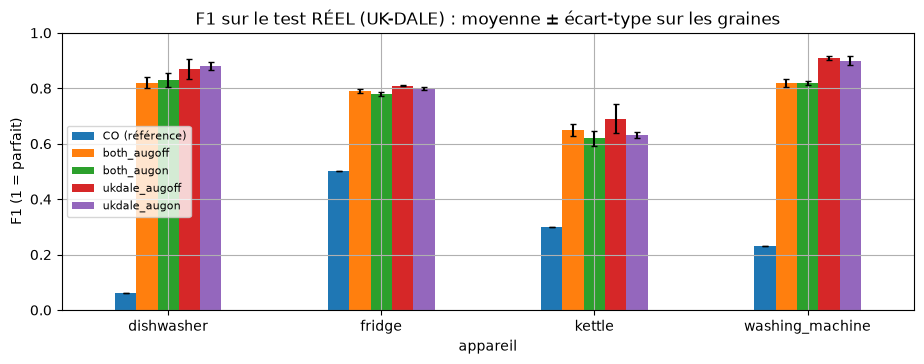

Une différence entre deux configurations n'est crédible que si elle dépasse l'écart-type (et qu'il y a ≥ 3 graines).
Synthèse mise à jour : runs_s6/synthese_F1.csv et runs_s6/synthese_F1.png


,CO (référence),both_augoff,both_augon,ukdale_augoff,ukdale_augon
appareil,,,,,
dishwasher,0.06 ± 0.0,0.82 ± 0.02,0.83 ± 0.02,0.87 ± 0.04,0.88 ± 0.01
fridge,0.5 ± 0.0,0.79 ± 0.01,0.78 ± 0.01,0.81 ± 0.0,0.8 ± 0.0
kettle,0.3 ± 0.0,0.65 ± 0.02,0.62 ± 0.03,0.69 ± 0.05,0.63 ± 0.01
washing_machine,0.23 ± 0.0,0.82 ± 0.01,0.82 ± 0.01,0.91 ± 0.01,0.9 ± 0.02
nombre de graines,-,3,3,3,3


In [25]:
from IPython.display import display
# sauvegarde de cette exécution dans son dossier, puis comparaison de toutes les exécutions déjà faites
results.round(4).to_csv(OUT_DIR / "resultats_nilm.csv")
shift_res.round(3).to_csv(OUT_DIR / "decalables.csv")
if sim_res is not None: sim_res.round(4).to_csv(OUT_DIR / "resultats_simule.csv")
flex_res.round(3).to_csv(RUNS_DIR / "flexibilite_commune.csv")    # identique pour tous les runs (vraies courbes) : un seul fichier
print("fichiers écrits dans", OUT_DIR, ":", sorted(p.name for p in OUT_DIR.iterdir()))

# regroupe les exécutions par configuration (tout sauf la graine) et calcule moyenne ± écart-type sur les graines
frames = []
for f in sorted(RUNS_DIR.glob("*/resultats_nilm.csv")):
    m_ = re.match(r"(.*?)_s(\d+)$", f.parent.name)
    cfg_, seed_ = (m_.group(1), m_.group(2)) if m_ else (f.parent.name, "-")
    r_ = pd.read_csv(f, index_col=[0, 1]).xs("Réseau", level="méthode")["F1"]
    frames.append((cfg_, seed_, r_))
if frames:
    co = pd.read_csv(sorted(RUNS_DIR.glob("*/resultats_nilm.csv"))[0], index_col=[0, 1]).xs("CO", level="méthode")["F1"]
    allf1 = pd.DataFrame({f"{c}|{s_}": r_ for c, s_, r_ in frames})
    cfgs = sorted({c for c, _, _ in frames})
    mean = pd.DataFrame({c: allf1[[k for k in allf1 if k.split("|")[0] == c]].mean(axis=1) for c in cfgs})
    std = pd.DataFrame({c: allf1[[k for k in allf1 if k.split("|")[0] == c]].std(axis=1).fillna(0) for c in cfgs})
    nseed = {c: sum(1 for k in allf1 if k.split("|")[0] == c) for c in cfgs}
    mean.insert(0, "CO (référence)", co); std.insert(0, "CO (référence)", 0.0)
    fig, ax = plt.subplots(figsize=(11, 3.6))
    mean.round(2).plot.bar(yerr=std, rot=0, ax=ax, ylim=(0, 1), capsize=2, title="F1 sur le test RÉEL (UK-DALE) : moyenne ± écart-type sur les graines")
    ax.set_ylabel("F1 (1 = parfait)"); ax.legend(fontsize=8)
    fig.savefig(RUNS_DIR / "synthese_F1.png", dpi=150, bbox_inches="tight")
    rapport("13. Réel contre simulé", "F1 sur le test réel selon la configuration (moyenne ± écart-type)", fig); plt.show()
    tab = mean.round(2).astype(str) + " ± " + std.round(2).astype(str)
    tab.loc["nombre de graines"] = ["-"] + [str(nseed[c]) for c in cfgs]
    tab.to_csv(RUNS_DIR / "synthese_F1.csv")
    print("Une différence entre deux configurations n'est crédible que si elle dépasse l'écart-type (et qu'il y a ≥ 3 graines).")
    print("Synthèse mise à jour :", RUNS_DIR / "synthese_F1.csv", "et", RUNS_DIR / "synthese_F1.png")
    rapport("13. Réel contre simulé", "F1 sur le test réel : toutes les configurations", tab)
    display(tab)


## 13b. Test sur une autre maison réelle (UK-DALE maison 2)
C'est le test le plus parlant pour le client : le réseau n'a **jamais** vu cette maison (autres appareils, autres habitudes, autre compteur). La cellule lit les fichiers `labels.dat` et `channel_N.dat` de la maison 2, au même format que la maison 1 (avec une table de correspondance des noms, par exemple `dish_washer` → `dishwasher`), applique le réseau tel quel et calcule les mêmes scores.

Les échelles de puissance restent celles apprises sur la maison 1 : un frigo plus ou moins puissant dans la maison 2 fera baisser le score, et c'est ce que l'augmentation de gain cherche à atténuer.

Dans l'état actuel, `H2_DIR = None` : je n'ai pas encore téléchargé la maison 2, la cellule est donc sautée. Ce test fait partie de la suite du travail.

In [26]:
# --- Test sur une AUTRE maison réelle (UK-DALE house_2) : le vrai test de généralisation ---
# À préparer : un dossier avec labels.dat + channel_N.dat de la maison 2 (mêmes noms de fichiers qu'en maison 1). Laisse None pour sauter.
H2_DIR = None            # ex. Path.home() / "Desktop/MASTER/Projet/Modele_IA/house_2"
H2_LOAD = ("2013-02-17", "2013-10-09")
H2_ALIAS = {"dish_washer": "dishwasher"}     # noms différents entre maisons

if H2_DIR is not None and Path(H2_DIR).exists():
    lab2 = {H2_ALIAS.get(k, k): v for k, v in read_labels(Path(H2_DIR)).items()}
    ser2 = {}
    for name in [MAINS] + APPLIANCES:
        if name not in lab2:
            print("absent de la maison 2 :", name); continue
        d = pd.read_csv(Path(H2_DIR) / f"channel_{lab2[name]}.dat", sep=r"\s+", header=None, usecols=[0, 1], names=["t", "w"])
        d.index = pd.to_datetime(d["t"], unit="s"); s2 = d["w"].astype(float)
        s2 = s2[~s2.index.duplicated()].sort_index().loc[H2_LOAD[0]:H2_LOAD[1]]
        ser2[name] = s2.resample(RESAMPLE).mean()
    app2 = [a for a in APPLIANCES if a in ser2]
    d2 = pd.DataFrame(ser2); d2 = d2.reindex(pd.date_range(d2.index.min(), d2.index.max(), freq=RESAMPLE))
    ok2 = d2.notna().all(axis=1).values; T2 = len(d2)
    agg2 = d2[MAINS].fillna(0).values.astype(np.float32)
    Yw2 = d2[app2].fillna(0).values.astype(np.float32).T
    idx_app = [APPLIANCES.index(a) for a in app2]
    rows2 = [agg2 / 1000.0]
    if USE_TIME:
        h2 = (d2.index.hour + d2.index.minute / 60).values
        rows2 += [np.sin(2 * np.pi * h2 / 24), np.cos(2 * np.pi * h2 / 24)]
    X2 = np.vstack(rows2).astype(np.float32); X2[:, ~ok2] = 0.0
    net.eval(); outs = []
    with torch.no_grad():
        Xt2 = torch.tensor(X2, device=device); CH_, CTX = 20000, 512
        for a in range(0, T2, CH_):
            lo = max(0, a - CTX); b = min(T2, a + CH_)
            outs.append(net(Xt2[:, lo:b].unsqueeze(0))[0][:, a - lo:].cpu().numpy())
    out2 = np.concatenate(outs, axis=1)
    reg2 = np.maximum(out2[idx_app], 0) * scale_y[idx_app, None]
    p2 = 1 / (1 + np.exp(-out2[n_app:][idx_app])); on2 = p2 > 0.5
    pred2 = reg2 * on2
    rows_h2 = []
    for j, a in enumerate(app2):
        i_ = APPLIANCES.index(a)
        rows_h2.append({"appareil": a, **metrics(Yw2[j, ok2], pred2[j, ok2], on2[j, ok2], thr[i_])})
    h2_res = pd.DataFrame(rows_h2).set_index("appareil")
    print(f"Maison 2 : {ok2.sum()} minutes valides sur {T2}. Réseau entraîné uniquement avec la maison 1 (et/ou LPG).")
    h2_res.round(3).to_csv(OUT_DIR / "resultats_maison2.csv")
    rapport("13b. Autre maison réelle", "Test sur UK-DALE maison 2 (jamais vue)", h2_res.round(2))
    display(h2_res.round(2))
else:
    print("Test maison 2 ignoré (H2_DIR = None). Voir le texte au-dessus pour préparer les fichiers.")


Test maison 2 ignoré (H2_DIR = None). Voir le texte au-dessus pour préparer les fichiers.


## 14. Résultats et analyse

### Protocole des runs
J'ai lancé le notebook de haut en bas avec **SEED = 0, 1 et 2** pour 4 configurations, soit 12 runs :
- `TRAIN_ON = "ukdale"`, `GAIN_AUG = None` (référence), puis `GAIN_AUG = (0.5, 2.0)` ;
- `TRAIN_ON = "both"`, `GAIN_AUG = None`, puis `GAIN_AUG = (0.5, 2.0)`.

Chaque run range ses fichiers dans son propre dossier, et la section 13 met à jour la synthèse commune :

```
runs_s6/
├── synthese_F1.csv          ← tableau moyenne ± écart-type de toutes les configurations
├── synthese_F1.png          ← le graphique correspondant
├── flexibilite_commune.csv  ← identique pour tous les runs (vraie courbe de la maison)
├── ukdale_augoff_s0/
│   ├── resultats_nilm.csv
│   ├── resultats_simule.csv
│   ├── decalables.csv
│   ├── nilm_cnn.pt          ← poids du réseau
│   └── rapport.pdf          ← seulement si PDF = True
├── both_augon_s1/
│   └── …
```

Relancer un run écrase son dossier ; pour l'oublier, il suffit de supprimer son dossier puis de relancer la section 13.

### Synthèse sur le test réel (F1, moyenne ± écart-type sur 3 graines)

| Appareil | CO | `ukdale`, sans aug. | `ukdale`, aug. | `both`, sans aug. | `both`, aug. |
|---|---|---|---|---|---|
| Lave-vaisselle | 0,06 | **0,87 ± 0,04** | 0,88 ± 0,01 | 0,82 ± 0,02 | 0,83 ± 0,02 |
| Lave-linge | 0,23 | **0,91 ± 0,01** | 0,90 ± 0,02 | 0,82 ± 0,01 | 0,82 ± 0,01 |
| Frigo | 0,50 | **0,81 ± 0,00** | 0,80 ± 0,00 | 0,79 ± 0,01 | 0,78 ± 0,01 |
| Bouilloire | 0,30 | **0,69 ± 0,05** | 0,63 ± 0,01 | 0,65 ± 0,02 | 0,62 ± 0,03 |

- Les écarts d'une graine à l'autre sont faibles (0,00 à 0,05) : les résultats sont **reproductibles**.
- **UK-DALE seul, sans augmentation** reste la meilleure configuration sur la maison réelle, nettement pour le lave-linge (+0,09 par rapport à `both`).
- **L'augmentation de gain** n'apporte rien de significatif sur la maison 1 (différences dans l'écart-type) et dégrade la bouilloire : je ne la retiens pas tant qu'elle n'a pas montré d'effet sur une autre maison réelle.
- Ajouter les foyers simulés (`both`) coûte toujours un peu sur le réel, comme en semaine 5.

### Run de référence `ukdale_augoff_s0` (sorties affichées dans ce notebook)
| Appareil | F1 CO | F1 réseau | Précision | Rappel | Erreur d'énergie CO | Erreur d'énergie réseau |
|---|---|---|---|---|---|---|
| Lave-vaisselle | 0,06 | **0,87** | 0,78 | 0,99 | 363 % | 15 % |
| Lave-linge | 0,23 | **0,91** | 0,85 | 0,99 | 123 % | 2 % |
| Frigo | 0,50 | **0,81** | 0,76 | 0,87 | 23 % | 16 % |
| Bouilloire | 0,30 | **0,75** | 0,64 | 0,92 | 78 % | 26 % |

- **Matrices de confusion** : environ 1 % de fausses alertes ou moins sur les minutes éteintes pour la bouilloire, le lave-linge et le lave-vaisselle, et seulement 19 minutes de lave-vaisselle ratées sur tout l'hiver. Le frigo reste le cas le plus imparfait (20 % de fausses alertes), car ses 90 W se confondent avec les variations du reste de la maison.
- **Flexibilité** : 16,2 % d'économie en HP/HC et 32,7 % avec le prix dynamique synthétique (chauffe-eau + batterie), soit environ 244 à 344 €/an.
- **Appareils décalables** : l'économie potentielle estimée avec le réseau est à 3 % de la vraie pour le lave-linge en HP/HC (et à moins de 1 % avec le prix dynamique) ; l'écart est plus grand pour le lave-vaisselle (22 à 34 %, sur de petites sommes). Avec le CO, l'écart atteint 110 à 730 %.
- **Foyer simulé jamais vu** : F1 de 0,15 à 0,50, confirmation que la généralisation à une autre maison est la principale limite.

## 15. Export PDF de tous les résultats
Cette cellule rassemble dans **un seul PDF** (format A4, dans le dossier du run : `runs_s6/<run>/rapport.pdf`) tout ce qui a été produit pendant l'exécution : une page de garde avec les réglages et le verdict réseau contre CO, puis chaque **figure**, chaque **tableau** et chaque **texte d'interprétation**, dans l'ordre des sections.

Il n'est écrit que si `PDF = True` : je l'ai réservé au run de référence `ukdale_augoff_s0` (24 pages). La cellule s'exécute en dernier, automatiquement avec *Run All* ; une section non exécutée est simplement absente du PDF.

In [27]:
from matplotlib.backends.backend_pdf import PdfPages
from datetime import datetime

PDF_FILE = OUT_DIR / "rapport.pdf"
A4 = (8.27, 11.69)
TAB_ROWS = 30                                   # lignes de tableau par page
TXT_LINES, TXT_WIDTH = 70, 100                  # lignes de texte par page, caractères par ligne

def _cellule(v):
    if isinstance(v, (float, np.floating)):
        return "–" if not np.isfinite(v) else f"{v:,.2f}".replace(",", " ")
    if isinstance(v, (int, np.integer)):
        return f"{v:,}".replace(",", " ")
    return str(v)

class Rapport:
    def __init__(self, pdf):
        self.pdf, self.n = pdf, 0

    def page(self, section, titre):
        fig = plt.figure(figsize=A4)
        self.n += 1
        fig.text(0.06, 0.965, section, fontsize=9, color="#777")
        fig.text(0.06, 0.94, titre, fontsize=13, weight="bold")
        fig.text(0.94, 0.02, f"NILM – {RUN_TAG} – page {self.n}", fontsize=7, color="#999", ha="right")
        return fig

    def fin(self, fig):
        self.pdf.savefig(fig); plt.close(fig)

    def figure(self, section, titre, png):
        img = plt.imread(io.BytesIO(png))
        fig = self.page(section, titre)
        ax = fig.add_axes([0.06, 0.05, 0.88, 0.86]); ax.imshow(img); ax.set_anchor("N"); ax.axis("off")
        self.fin(fig)

    def tableau(self, section, titre, df):
        df = df.reset_index() if not isinstance(df.index, pd.RangeIndex) else df
        cols = ["\n".join(textwrap.wrap(str(c), 14)) or " " for c in df.columns]
        rows = [[_cellule(v) for v in r] for r in df.itertuples(index=False)]
        for k in range(0, max(len(rows), 1), TAB_ROWS):
            part = rows[k:k + TAB_ROWS]
            fig = self.page(section, titre + (f" (suite {k // TAB_ROWS + 1})" if k else ""))
            ax = fig.add_axes([0.04, 0.05, 0.92, 0.86]); ax.axis("off")
            if not part:
                ax.text(0, 1, "(tableau vide)", va="top"); self.fin(fig); continue
            tb = ax.table(cellText=part, colLabels=cols, loc="upper center", cellLoc="center")
            tb.auto_set_font_size(False); tb.set_fontsize(7); tb.scale(1, 1.35)
            tb.auto_set_column_width(list(range(len(cols))))
            for (r, c), cell in tb.get_celld().items():
                cell.set_edgecolor("#CCC")
                if r == 0:
                    cell.set_height(cell.get_height() * 2.3); cell.set_facecolor("#E3EEF0"); cell.set_text_props(weight="bold")
                elif r % 2 == 0:
                    cell.set_facecolor("#F7F7F7")
            self.fin(fig)

    def texte(self, section, titre, txt):
        lines = []
        for l in str(txt).splitlines() or [""]:
            lines += textwrap.wrap(l, TXT_WIDTH, subsequent_indent="    ") or [""]
        for k in range(0, len(lines), TXT_LINES):
            fig = self.page(section, titre + (f" (suite {k // TXT_LINES + 1})" if k else ""))
            fig.text(0.06, 0.91, "\n".join(lines[k:k + TXT_LINES]), fontsize=7.5, family="monospace", va="top", linespacing=1.35)
            self.fin(fig)

# --- page de garde : réglages, chiffres clés et verdict ---
g = globals()
garde = [f"Généré le {datetime.now():%d/%m/%Y à %H:%M}", "",
         f"Données d'entraînement (RUN_TAG) : {RUN_TAG}   |   calcul sur : {device}",
         f"UK-DALE : {DATA_DIR}", f"période lue : {LOAD[0]} -> {LOAD[1]}, pas {RESAMPLE}",
         f"appareils : {', '.join(APPLIANCES)}",
         f"seuils « allumé » (W) : {ON_W}",
         f"test = {TEST_FRAC:.0%} de la fin, validation = {VAL_FRAC:.0%} juste avant", ""]
if "n_par" in g:
    garde.append(f"réseau : {n_par} paramètres (≈ {n_par * 4 / 1024:.0f} Ko float32, ≈ {n_par / 1024:.0f} Ko int8)")
if "best_val" in g:
    garde.append(f"époques : {len(hist)} | meilleure perte de validation : {best_val:.4f}")
if "offset" in g:
    garde.append(f"consommation de fond estimée : {offset:.0f} W")
if "cmp" in g:
    gagne = [a for a in cmp.index if cmp.loc[a, "gain F1"] > 0]
    garde += ["", f"VERDICT : le réseau bat le CO (F1) sur {len(gagne)} appareil(s) sur {len(cmp)}"
                  + (f" : {', '.join(gagne)}" if gagne else ""), ""]
    garde += [f"   {a:16s} F1 CO {cmp.loc[a, 'F1 CO']:.2f} -> réseau {cmp.loc[a, 'F1 réseau']:.2f}  (gain {cmp.loc[a, 'gain F1']:+.2f})"
              for a in cmp.index]
if "flex_res" in g:
    best_ = flex_res["économie (%)"].groupby(level="prix").idxmax()
    garde += ["", "Flexibilité, meilleur scénario par signal de prix :"]
    garde += [f"   prix {pm:10s} {sc:28s} économie {flex_res.loc[(pm, sc), 'économie (%)']:.1f} %" for pm, sc in best_.values]

if PDF:
    with PdfPages(PDF_FILE) as pdf:
        rp = Rapport(pdf)
        fig = rp.page("Rapport de résultats", "NILM – réseau de neurones, confusion, flexibilité")
        garde += ["", "Contenu :"] + [f"   {s}" for s in dict.fromkeys(s for s, _ in RAPPORT.values())]
        fig.text(0.06, 0.90, "\n".join(garde), fontsize=8.5, va="top", family="monospace", linespacing=1.45)
        rp.fin(fig)
        for titre, (section, obj) in RAPPORT.items():
            if isinstance(obj, bytes):
                rp.figure(section, titre, obj)
            elif isinstance(obj, pd.DataFrame):
                rp.tableau(section, titre, obj)
            else:
                rp.texte(section, titre, obj)
        meta = pdf.infodict()
        meta["Title"] = f"Rapport NILM ({RUN_TAG})"; meta["Subject"] = "Désagrégation, confusion, flexibilité"

    print(f"PDF écrit : {PDF_FILE.resolve()}  ({rp.n} pages, {len(RAPPORT)} éléments)")

else:
    print("PDF non demandé (PDF = False dans les réglages) : mets PDF = True pour le run que tu veux présenter.")


PDF écrit : ~/Desktop/MASTER/Projet/Modele_IA/runs_s6/ukdale_augoff_s0/rapport.pdf  (24 pages, 23 éléments)


## 16. Conclusion : le modèle retenu

**Choix final.** Je retiens le réseau entraîné sur **UK-DALE seul, sans augmentation** (run `ukdale_augoff_s0`, poids dans `runs_s6/ukdale_augoff_s0/nilm_cnn.pt`). C'est la configuration la meilleure sur la maison réelle, avec des résultats stables d'une graine à l'autre. C'est ce modèle qui est exporté vers la carte STM32N6 en semaine 7.

**Le modèle.** Réseau convolutif 1D dilaté à connexions résiduelles : convolution d'entrée 1×1 (3 → 32 canaux), 7 blocs de convolution de noyau 3 avec des dilatations de 1 à 64 minutes, convolution de sortie 1×1 (32 → 8 canaux). **22 120 paramètres**, soit ≈ 86 Ko en float32 et ≈ 22 Ko en int8. Chaque minute de sortie dépend de 127 minutes avant et 127 minutes après.

**Entrées** (une valeur par minute, 3 canaux) :
1. la puissance totale de la maison en kW (moyenne sur la minute) ;
2. sin(2π·heure/24) ;
3. cos(2π·heure/24).

**Sorties** (8 canaux par minute) :
- canaux 0 à 3 : puissance normalisée du frigo, de la bouilloire, du lave-linge et du lave-vaisselle ; en watts, W = max(sortie, 0) × échelle (≈ 250 / 2 405 / 1 975 / 2 392 W) ;
- canaux 4 à 7 : score « allumé » de chaque appareil (allumé si le score est positif, c'est-à-dire une probabilité > 0,5) ; la puissance est mise à 0 quand l'appareil est déclaré éteint.

**Performances** (test réel, 11 novembre 2013 – 28 février 2014, jamais vu à l'entraînement) :
- F1 de **0,75 à 0,91** (lave-linge 0,91, lave-vaisselle 0,87, frigo 0,81, bouilloire 0,75) contre 0,06 à 0,50 pour le CO ;
- erreur d'énergie de **2 à 26 %** contre 23 à 363 % pour le CO ;
- variabilité d'un entraînement à l'autre : ±0,00 à ±0,05 de F1.

**Intérêt pour le projet.**
- Un **seul capteur** au tableau électrique remplace une prise connectée par appareil.
- La désagrégation est assez fiable pour **chiffrer et piloter la flexibilité** : économie potentielle des appareils décalables estimée à quelques % près, et 16 à 33 % d'économie simulée avec un chauffe-eau et une batterie pilotés selon le prix.
- Le modèle est **assez petit pour tourner sur le microcontrôleur** du capteur : seule l'énergie par appareil est envoyée par NB-IoT, et non la courbe brute.

**Limites.**
- Entraîné sur **une seule maison britannique** : sur un foyer jamais vu, le F1 tombe sous 0,5. Il faudra un test sur une autre maison réelle (UK-DALE maison 2) et, à terme, un réajustement avec quelques jours de mesures de la maison équipée.
- Entrée en puissance **apparente** (VA) comme la pince d'UK-DALE : cohérent avec un capteur de courant (CT) ou la TIC du Linky, à vérifier sur les vraies mesures.
- Le contexte de 127 minutes « après » impose un **retard d'environ 2 h** : adapté au suivi de consommation et à la planification, pas au pilotage instantané.
- Flexibilité évaluée avec des prix synthétiques connus à l'avance et des équipements simulés.